In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
import pingouin as pg

In [2]:
h5="/Users/mollyshallow/Desktop/opto_metrics_result/20251212_LD_viralvgat.h5"
h5_newmice="/Users/mollyshallow/Desktop/opto_metrics_result/20251212_LD_viralvgat_newcohort.h5"

In [3]:
## use the below lines to clean up the conditions (will fix this so its not hard coded later)
df=pd.read_hdf(h5, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df['folder_path'].astype('str')))
df['filename']=df['filename'].astype('str')

df['capduration']=df['captureT']-df['timetointercept']


fr=200

nandf=cdc(df)
nans=np.where(nandf['captureT']>=290)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=290)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=290)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']

#in some trials, its finding the intercept frame before the drop frame, find a way to re-calculate time to intercept on these
fr = 200
DIST_THRESH = 5

needs_fix = (
    nandf['interceptframe'].notna() &
    nandf['cricketdrop'].notna() &
    (nandf['interceptframe'] < nandf['cricketdrop'])
)

needs_fix.sum()  # sanity check

nandf['corrected_interceptframe'] = nandf['interceptframe']

def find_post_drop_intercept(dist, drop, thresh=DIST_THRESH):
    """
    dist : list/array of distances
    drop : cricketdrop frame
    """
    try:
        dist_arr = np.asarray(dist, dtype=float)
    except Exception:
        return np.nan

    if drop >= len(dist_arr):
        return np.nan

    post = dist_arr[int(drop):]
    idx = np.where(post < thresh)[0]

    if len(idx) == 0:
        return np.nan

    return int(drop + idx[0])

for i in nandf.index[needs_fix]:
    nandf.at[i, 'corrected_interceptframe'] = find_post_drop_intercept(
        nandf.at[i, 'dist'],
        nandf.at[i, 'cricketdrop']
    )

nandf['corrected_timetointercept'] = (
    nandf['corrected_interceptframe'] - nandf['cricketdrop']
) / fr

nandf.loc[
    nandf['corrected_interceptframe'].isna(),
    'corrected_timetointercept'
] = np.nan

nandf['corrected_capduration'] = (
    nandf['captureT'] - nandf['corrected_timetointercept']
)
fixed = needs_fix & nandf['corrected_interceptframe'].notna()
print(f"Intercepts needing fix: {needs_fix.sum()}")
print(f"Intercepts fixed: {fixed.sum()}")

nandf.loc[
    nandf['corrected_interceptframe'] < nandf['cricketdrop'],
    ['interceptframe', 'cricketdrop', 'corrected_interceptframe']
]


test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)


drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

start_cohort1_baseline_l = dt.strptime('2025-04-08', "%Y-%m-%d")
end_cohort1_baseline_l = dt.strptime('2025-04-14', "%Y-%m-%d")

start_cohort1_baseline_d = dt.strptime('2025-04-15', "%Y-%m-%d")
end_cohort1_baseline_d = dt.strptime('2025-04-19', "%Y-%m-%d")

start_cohort1_l_63 = dt.strptime('2025-04-21', "%Y-%m-%d")
end_cohort1_l_63 = dt.strptime('2025-04-26', "%Y-%m-%d")

start_cohort1_d_63 = dt.strptime('2025-04-28', "%Y-%m-%d")
end_cohort1_d_63 = dt.strptime('2025-05-01', "%Y-%m-%d")

start_cohort1_l_35 = dt.strptime('2025-05-05', "%Y-%m-%d")
end_cohort1_l_35 = dt.strptime('2025-05-09', "%Y-%m-%d")

start_cohort1_d_35 = dt.strptime('2025-05-12', "%Y-%m-%d")
end_cohort1_d_35 = dt.strptime('2025-05-17', "%Y-%m-%d")

test_nandf['condition']=test_nandf['condition'].astype(str)

indices=np.asarray(test_nandf.index)

for i in indices:
    if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
        if test_nandf['condition'][i]!=[0]:
            test_nandf.at[i, 'condition']='baseline_l'
  
    elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l_63:
        if test_nandf['condition'][i]!=[0]:
            test_nandf.at[i, 'condition']='baseline_d'
        
    elif start_cohort1_l_35<=test_nandf['timestamps'][i]<=start_cohort1_d_35:
        if test_nandf['condition'][i]!=[0]:
            test_nandf.at[i, 'condition']='3'
        
    elif start_cohort1_d_35<=test_nandf['timestamps'][i]<=end_cohort1_d_35:
        if test_nandf['condition'][i]!=[0]:
            test_nandf.at[i, 'condition']='4'
        

# indices=np.asarray(test_nandf.index)
# for i in indices:
#     if test_nandf['condition'][i]=='9':
#         test_nandf.at[i, 'condition']='2'

lower_laser_power=test_nandf[test_nandf['condition'].str.contains('3|4', na=False)]
higher_laser_power=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
# cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
# cleaned_conds_keep

baseline_trials=test_nandf[test_nandf['condition'].str.contains('baseline_l|baseline_d', na=False)]
# cleaned_baseline_trials=baseline_trials[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]


hue_order=[1,0]
palette=['#2976bb','#929591']

Intercepts needing fix: 412
Intercepts fixed: 412


In [4]:
## use the below lines to clean up the conditions (will fix this so its not hard coded later)
df=pd.read_hdf(h5_newmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df['folder_path'].astype('str')))
df['filename']=df['filename'].astype('str')

df['capduration']=df['captureT']-df['timetointercept']


fr=200

nandf=cdc(df)
nans=np.where(nandf['captureT']>=290)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=290)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=290)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']

#in some trials, its finding the intercept frame before the drop frame, find a way to re-calculate time to intercept on these
fr = 200
DIST_THRESH = 5

needs_fix = (
    nandf['interceptframe'].notna() &
    nandf['cricketdrop'].notna() &
    (nandf['interceptframe'] < nandf['cricketdrop'])
)

needs_fix.sum()  # sanity check

nandf['corrected_interceptframe'] = nandf['interceptframe']

def find_post_drop_intercept(dist, drop, thresh=DIST_THRESH):
    """
    dist : list/array of distances
    drop : cricketdrop frame
    """
    try:
        dist_arr = np.asarray(dist, dtype=float)
    except Exception:
        return np.nan

    if drop >= len(dist_arr):
        return np.nan

    post = dist_arr[int(drop):]
    idx = np.where(post < thresh)[0]

    if len(idx) == 0:
        return np.nan

    return int(drop + idx[0])

for i in nandf.index[needs_fix]:
    nandf.at[i, 'corrected_interceptframe'] = find_post_drop_intercept(
        nandf.at[i, 'dist'],
        nandf.at[i, 'cricketdrop']
    )

nandf['corrected_timetointercept'] = (
    nandf['corrected_interceptframe'] - nandf['cricketdrop']
) / fr

nandf.loc[
    nandf['corrected_interceptframe'].isna(),
    'corrected_timetointercept'
] = np.nan

nandf['corrected_capduration'] = (
    nandf['captureT'] - nandf['corrected_timetointercept']
)
fixed = needs_fix & nandf['corrected_interceptframe'].notna()
print(f"Intercepts needing fix: {needs_fix.sum()}")
print(f"Intercepts fixed: {fixed.sum()}")

nandf.loc[
    nandf['corrected_interceptframe'] < nandf['cricketdrop'],
    ['interceptframe', 'cricketdrop', 'corrected_interceptframe']
]


test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)


drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

start_cohort1_baseline_l = dt.strptime('2025-10-21', "%Y-%m-%d")
end_cohort1_baseline_l = dt.strptime('2025-10-24', "%Y-%m-%d")

start_cohort1_baseline_d = dt.strptime('2025-10-28', "%Y-%m-%d")
end_cohort1_baseline_d = dt.strptime('2025-10-31', "%Y-%m-%d")

start_cohort1_l_63 = dt.strptime('2025-11-02', "%Y-%m-%d")
end_cohort1_l_63 = dt.strptime('2025-11-06', "%Y-%m-%d")

start_cohort1_d_63 = dt.strptime('2025-11-07', "%Y-%m-%d")
end_cohort1_d_63 = dt.strptime('2025-11-11', "%Y-%m-%d")


test_nandf['condition']=test_nandf['condition'].astype(str)

indices=np.asarray(test_nandf.index)

for i in indices:
    if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
        if test_nandf['condition'][i]!=[0]:
            test_nandf.at[i, 'condition']='baseline_l'
  
    elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l_63:
        if test_nandf['condition'][i]!=[0]:
            test_nandf.at[i, 'condition']='baseline_d'
        
        

# indices=np.asarray(test_nandf.index)
# for i in indices:
#     if test_nandf['condition'][i]=='9':
#         test_nandf.at[i, 'condition']='2'

# lower_laser_power=test_nandf[test_nandf['condition'].str.contains('3|4', na=False)]
new_cohort=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
# cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
# cleaned_conds_keep

baseline_trials_new=test_nandf[test_nandf['condition'].str.contains('baseline_l|baseline_d', na=False)]
# cleaned_baseline_trials=baseline_trials[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]


hue_order=[1,0]
palette=['#2976bb','#929591']

Intercepts needing fix: 335
Intercepts fixed: 335


In [46]:
hue_order=[1,0]
palette=['#2976bb','#929591']

In [5]:
all_data=pd.concat([higher_laser_power, new_cohort], ignore_index=True)

In [6]:
all_data

,filename,folder_path,condition,laser_value,trials_to_drop,dist,cricket_spd,mouse_spd,az,captureT,...,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,corrected_timetointercept,corrected_capduration,corrected_interceptframe,timestamps
0,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-06-38_mouse-3352,1.0,0.0,left_only,"[32.68468429206058, 32.725606419352125, 33.167...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.820464707482329, 6.110512209286836, 7.87394...","[171.58462568552525, 173.22566975453293, 172.9...",19.790,...,0.333333,1.000000,10.500,2100.0,6.31000,9.290,5.245,14.545,2100.0,2025-04-21 09:06:38
1,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-08-51_mouse-3352,1.0,0.0,left_only,"[nan, 62.564342588310225, 62.57847470293101, 6...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.61692133588647, 10.755066775654555, 14.1260...","[nan, 60.12358977941303, 59.34726236587227, 58...",64.220,...,0.421053,0.125000,13.215,2643.0,8.40875,51.005,9.335,54.885,2643.0,2025-04-21 09:08:51
2,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-11-12_mouse-3352,1.0,1.0,left_only,"[54.24384508435525, 54.21612013599778, 54.1846...","[0.3435990171514824, 0.3412039639408997, 0.332...","[2.257058244768242, 2.4430166816952377, 2.3890...","[71.18839914253688, 62.717046231484645, 55.529...",94.125,...,0.038462,1.000000,89.815,17963.0,9.93950,4.310,89.595,4.530,17963.0,2025-04-21 09:11:12
3,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-14-42_mouse-3352,1.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[2.7024922221323444, 3.107084745186775, 4.1402...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",23.975,...,0.181818,0.500000,4.845,969.0,11.50250,19.130,1.100,22.875,2974.0,2025-04-21 09:14:42
4,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-17-16_mouse-3352,1.0,1.0,left_only,"[43.52936425762324, 43.53401160997311, 43.5396...","[0.5899277518092662, 0.6615877426062879, 2.121...","[0.18431865367242262, 0.211156300008769, 1.122...","[85.6227143575294, 85.29555370906299, 84.99610...",29.320,...,1.000000,1.000000,12.310,2462.0,10.12450,17.010,12.310,17.010,2462.0,2025-04-21 09:17:16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
930,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-40-36_mouse-5096,2.0,0.0,left_only,"[nan, 40.39356288421923, 40.39763572151864, 40...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.253608241541986, 4.834900882753308, 5.56857...","[nan, 22.87018484616279, 21.525017302599842, 1...",65.320,...,0.294118,0.200000,30.090,6018.0,11.15575,35.230,29.850,35.470,6018.0,2025-11-11 13:40:36
931,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-42-44_mouse-5096,2.0,1.0,left_only,"[61.2818874604661, 61.18894543752171, 61.06944...","[0.742619405079549, 0.5379811470614261, 0.5398...","[10.271955141111093, 12.139244401985835, 12.93...","[124.85829793331533, 112.80212066064826, 110.5...",125.050,...,0.045455,1.000000,114.950,22990.0,12.00050,10.100,114.855,10.195,22990.0,2025-11-11 13:42:44
932,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-45-38_mouse-5096,2.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[12.47024290361598, 14.292803973486915, 15.115...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",21.495,...,0.333333,0.333333,5.500,1100.0,11.57900,15.995,5.365,16.130,3762.0,2025-11-11 13:45:38
933,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-47-54_mouse-5096,2.0,1.0,left_only,"[42.341014659077295, 42.35307252879992, 42.358...","[0.2234606983841554, 0.35161924225973723, 0.36...","[2.422817018547666, 2.6951104186283152, 3.4748...","[128.4053091369584, 127.87414258214403, 127.02...",NaN,...,0.142857,0.200000,83.950,16790.0,11.61925,NaN,83.485,NaN,16790.0

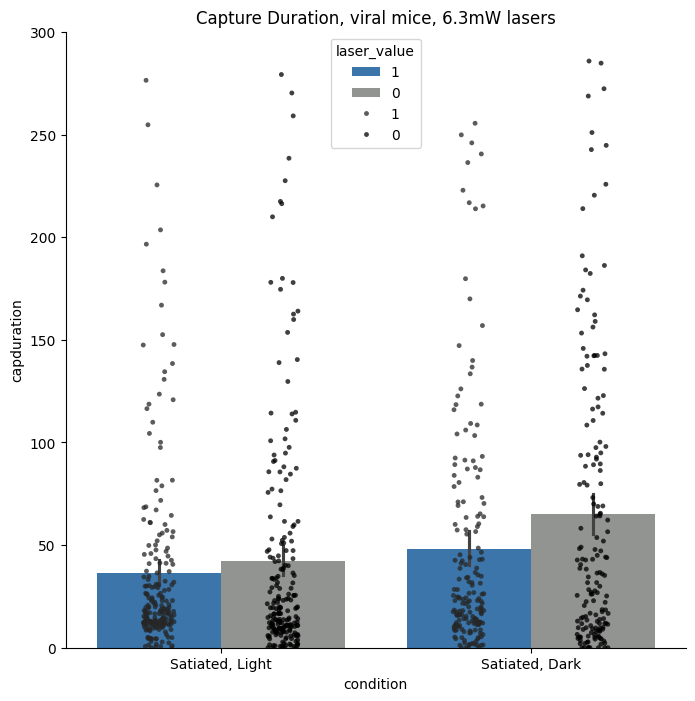

In [12]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=all_data, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=all_data, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, viral mice, 6.3mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

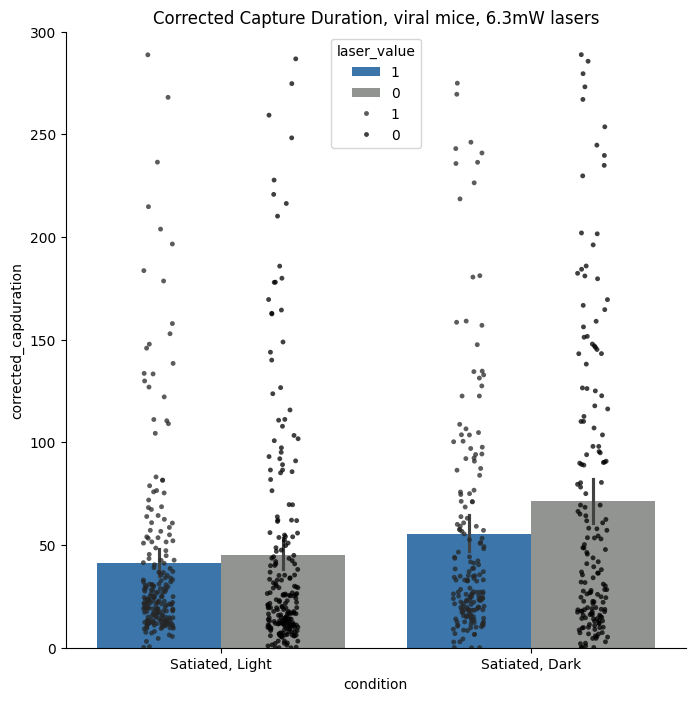

In [14]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=all_data, x='condition', y='corrected_capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='corrected_capduration', hue='laser_value',dodge=True, data=all_data, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Corrected Capture Duration, viral mice, 6.3mW lasers')
plt.ylim(0,300)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

In [17]:

from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = all_data.dropna(subset=["corrected_capduration", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["corrected_capduration"].dropna()
    group1 = group[group["laser_value"] == 1]["corrected_capduration"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0              211              214  -1.178043  0.238780
1       2.0              164              177   1.349555  0.177159


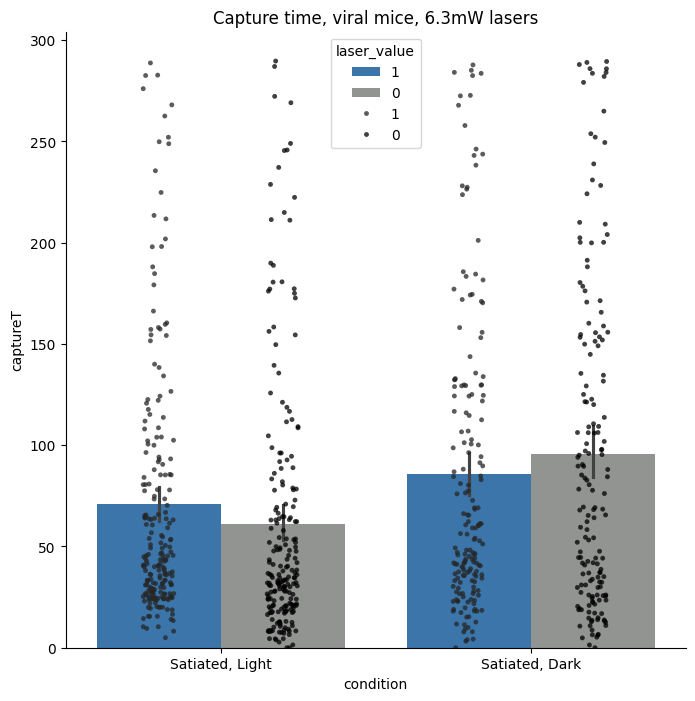

In [15]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=all_data, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=all_data, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture time, viral mice, 6.3mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

In [43]:

from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
all_data = all_data.dropna(subset=["capduration", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["captureT"].dropna()
    group1 = group[group["laser_value"] == 1]["captureT"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0              211              214  -2.956756  0.003109
1       2.0              164              177   0.722878  0.469755


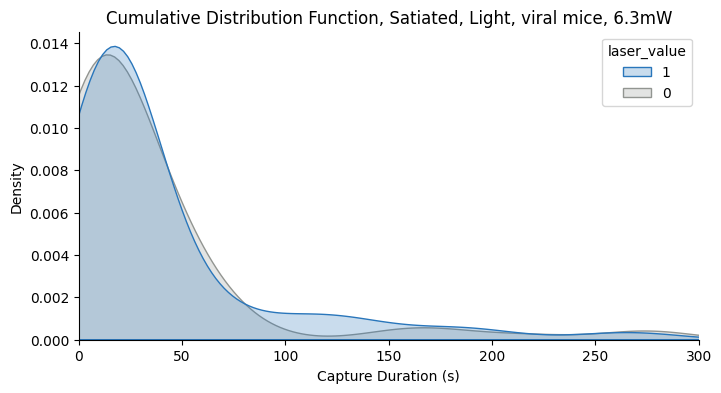

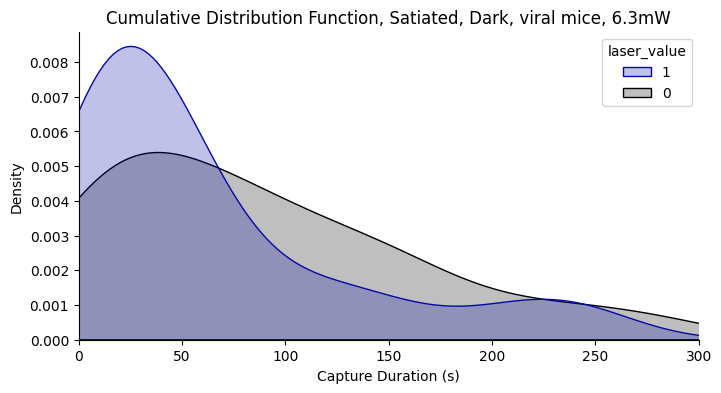

In [49]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=higher_laser_power.iloc[np.where(higher_laser_power['condition']=='1.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=higher_laser_power.iloc[np.where(higher_laser_power['condition']=='2.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 300)
# plt.ylim(0, 0.06)
sns.despine()

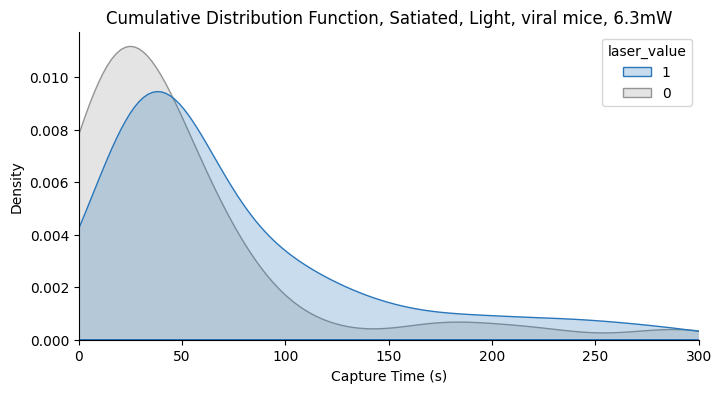

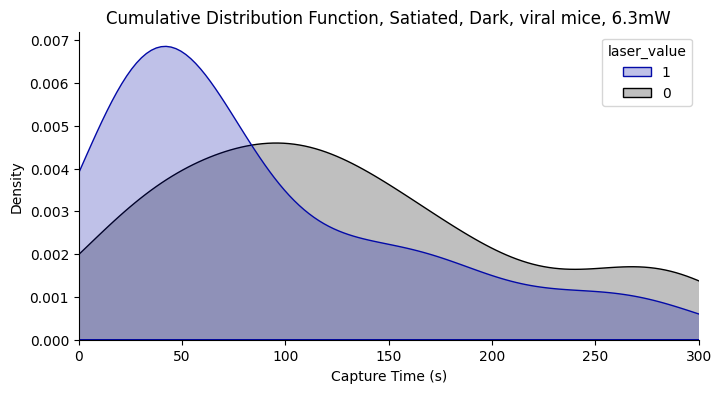

In [50]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=higher_laser_power.iloc[np.where(higher_laser_power['condition']=='1.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=higher_laser_power.iloc[np.where(higher_laser_power['condition']=='2.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()

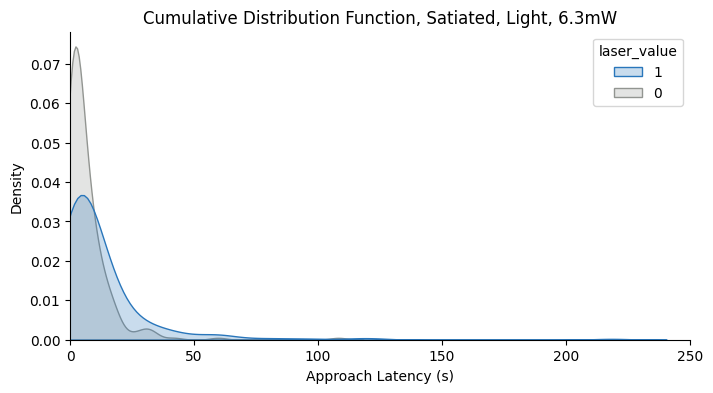

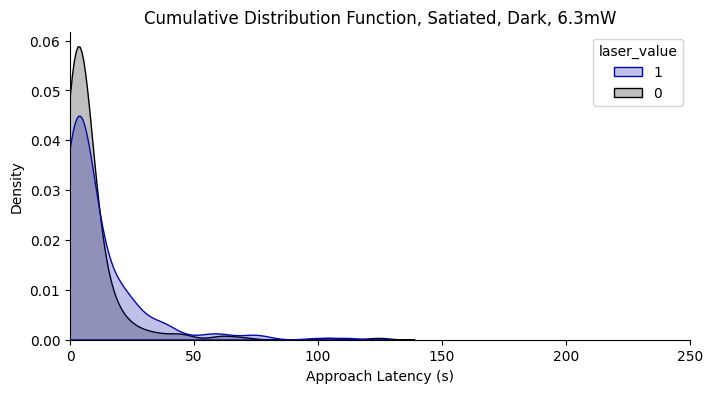

In [29]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=all_data.iloc[np.where(all_data['condition']=='1.0')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 250)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=all_data.iloc[np.where(all_data['condition']=='2.0')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 250)
# plt.ylim(0, 0.06)
sns.despine()

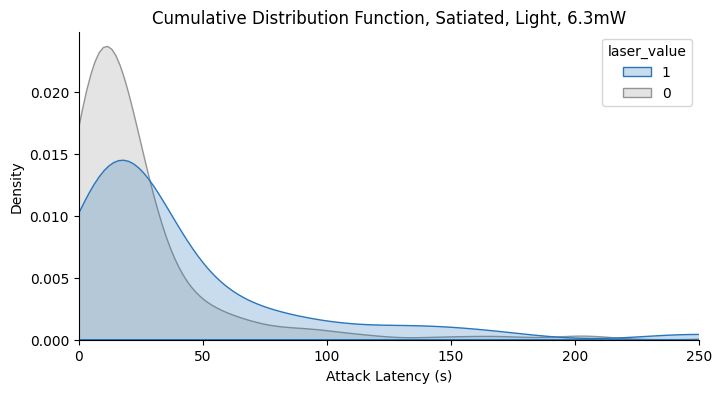

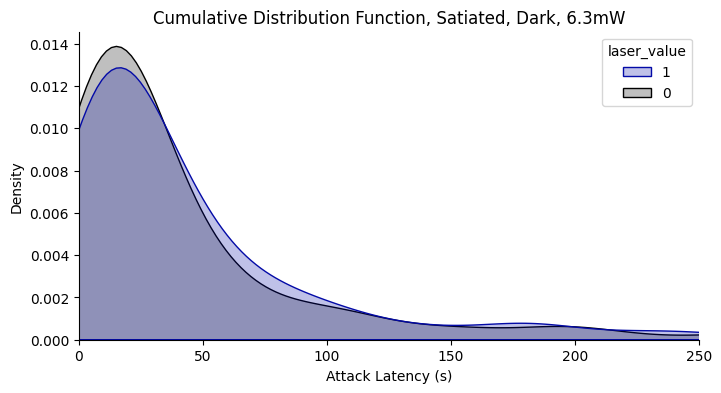

In [28]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=all_data.iloc[np.where(all_data['condition']=='1.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 250)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=all_data.iloc[np.where(all_data['condition']=='2.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 250)
# plt.ylim(0, 0.06)
sns.despine()

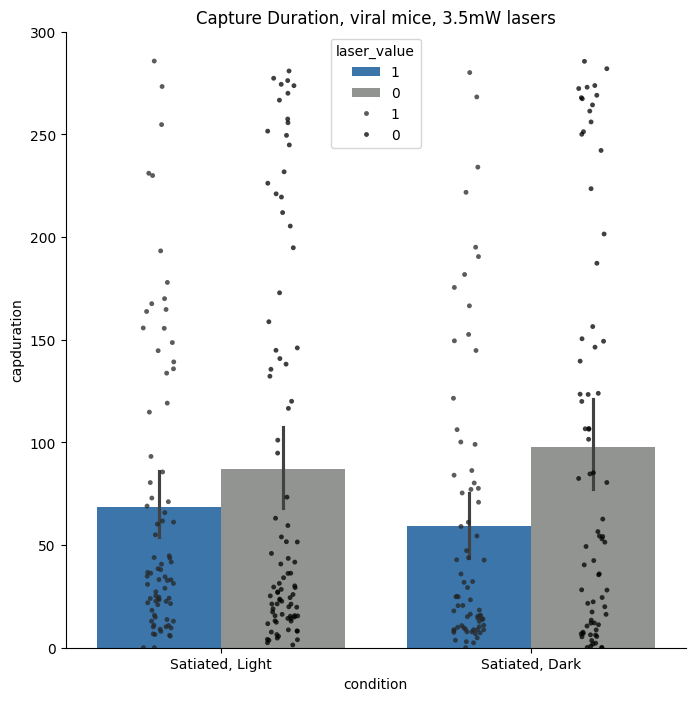

In [100]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=lower_laser_power, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=lower_laser_power, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, viral mice, 3.5mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

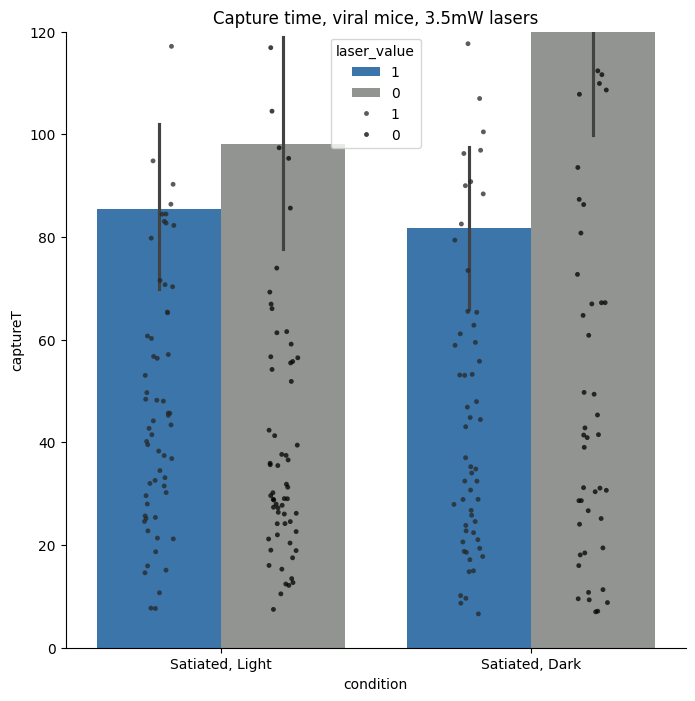

In [58]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=lower_laser_power, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=lower_laser_power, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture time, viral mice, 3.5mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

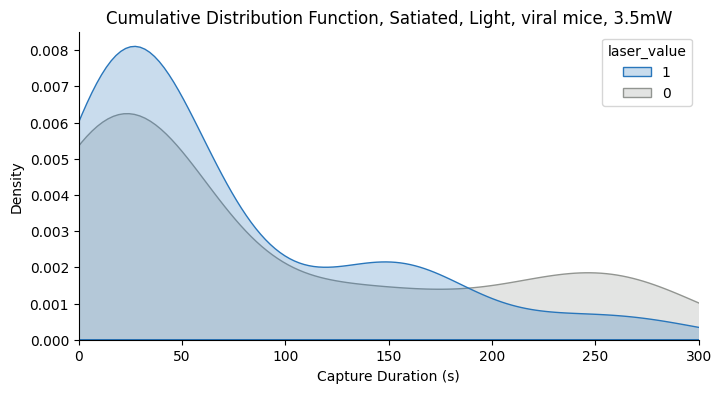

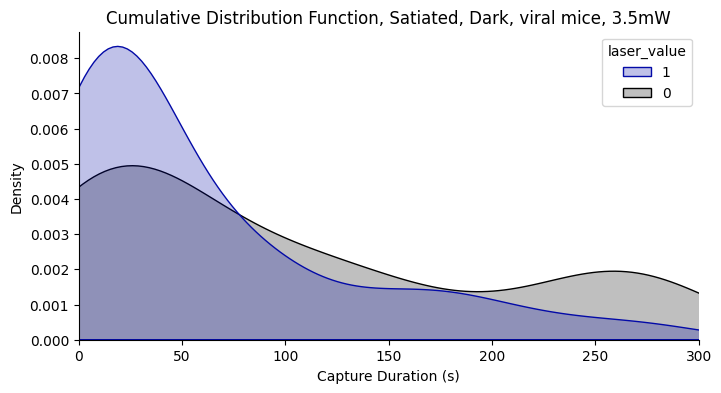

In [59]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='3')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='4')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()

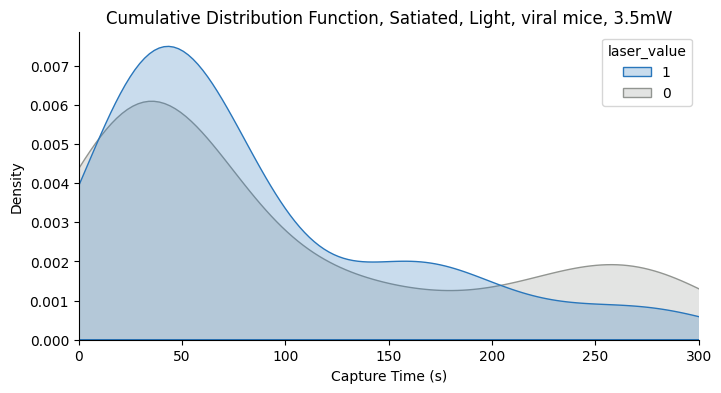

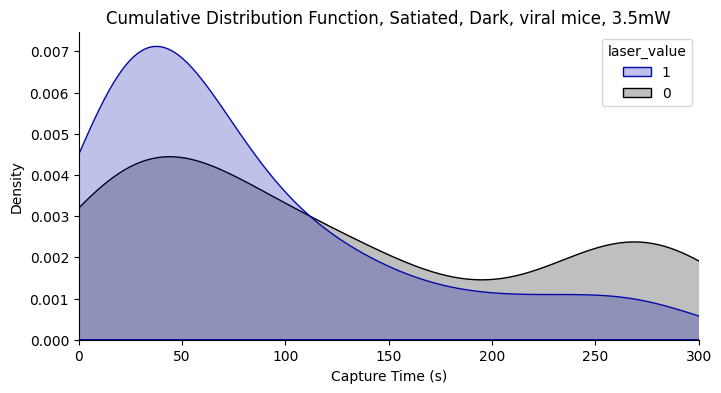

In [60]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='3')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='4')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()

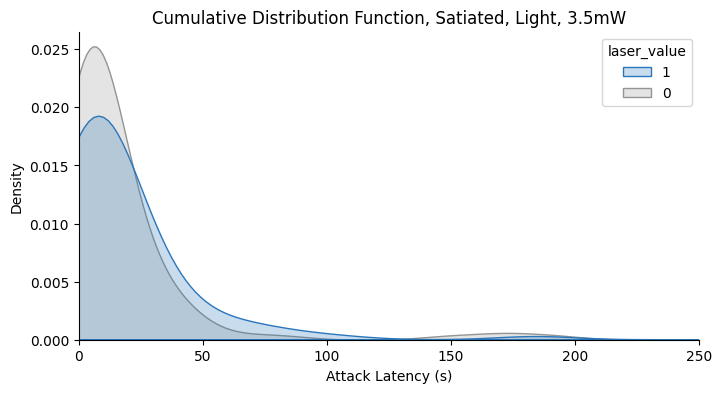

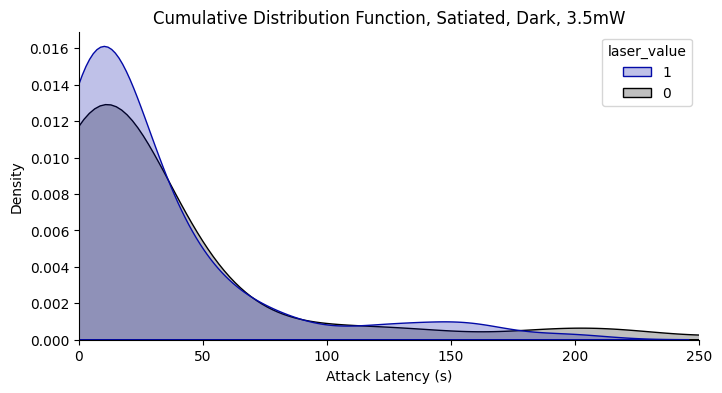

In [18]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='3')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 250)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='4')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 250)
# plt.ylim(0, 0.06)
sns.despine()

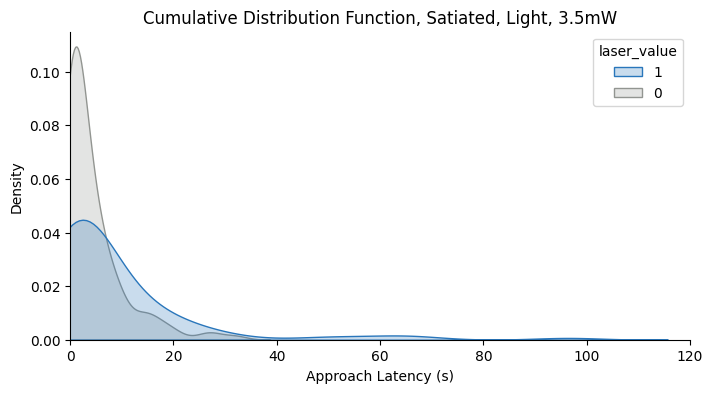

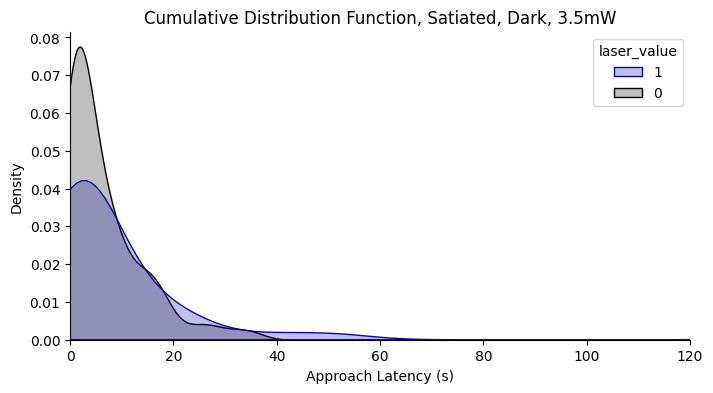

In [21]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='3')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='4')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()

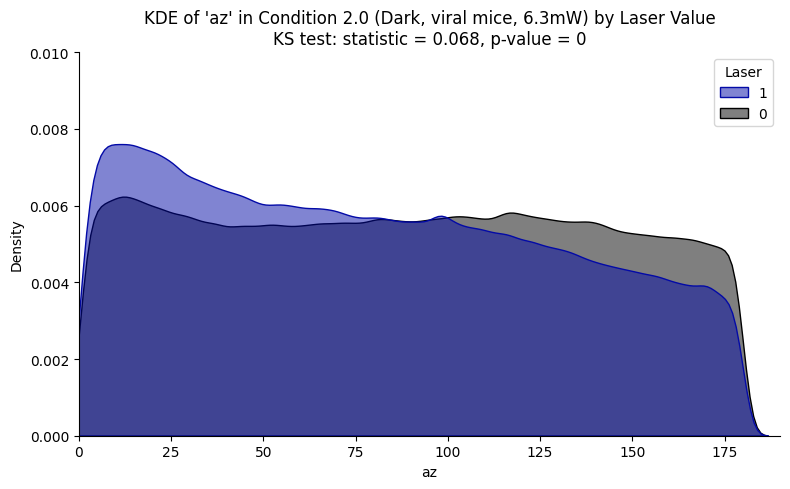

In [34]:

from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in all_data.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, viral mice, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
plt.ylim(0,0.010)
plt.tight_layout()
sns.despine()
plt.show()


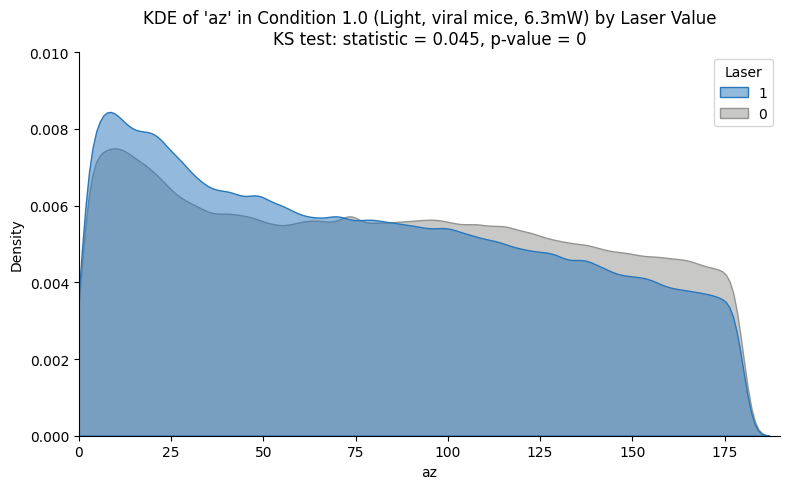

In [33]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in all_data.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, viral mice, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
plt.ylim(0,0.010)
plt.tight_layout()
sns.despine()
plt.show()


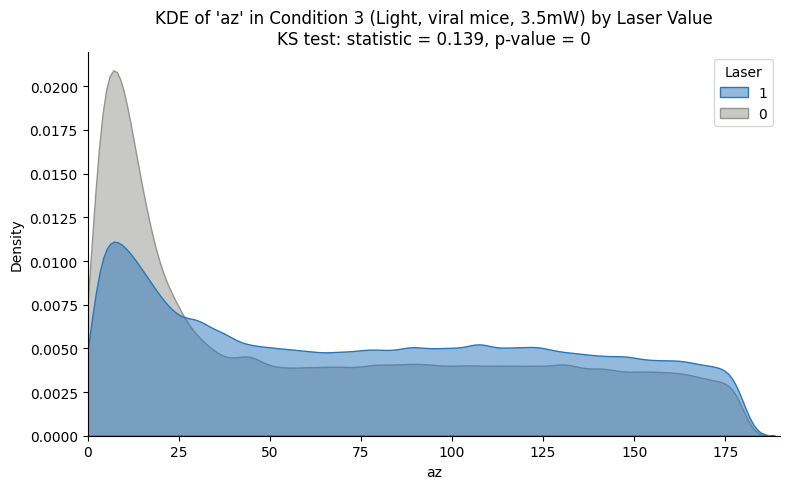

In [63]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '3'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in lower_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, viral mice, 3.5mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


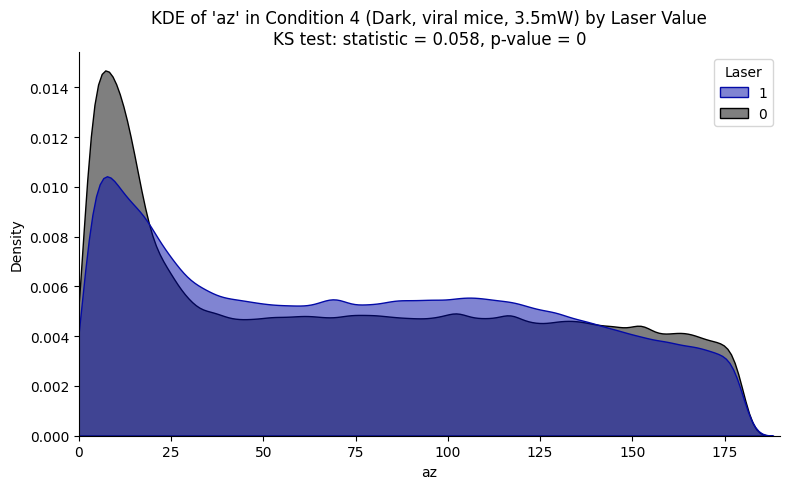

In [64]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '4'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in lower_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, viral mice, 3.5mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


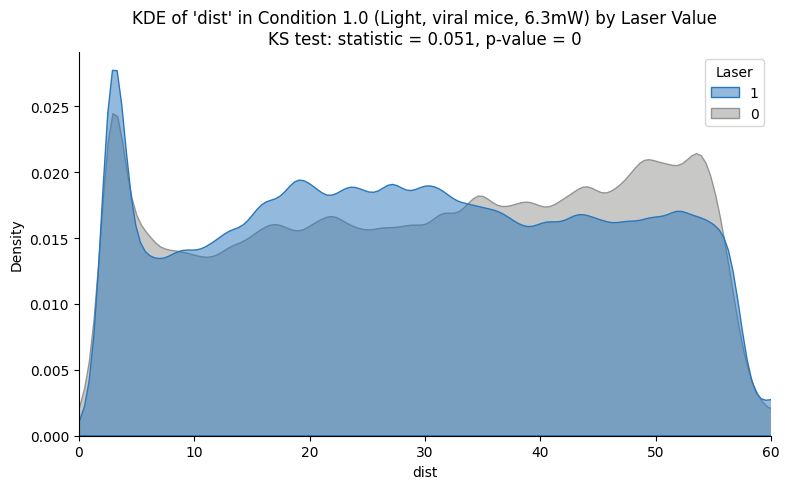

In [35]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in all_data.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, viral mice, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


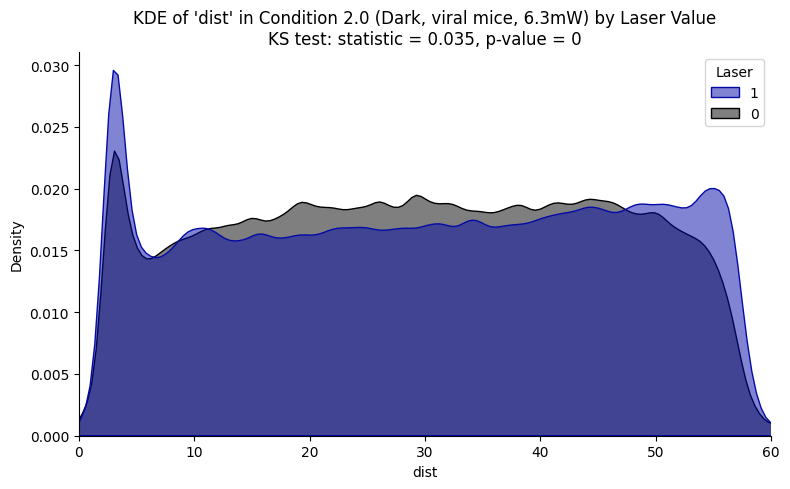

In [36]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in all_data.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, viral mice, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


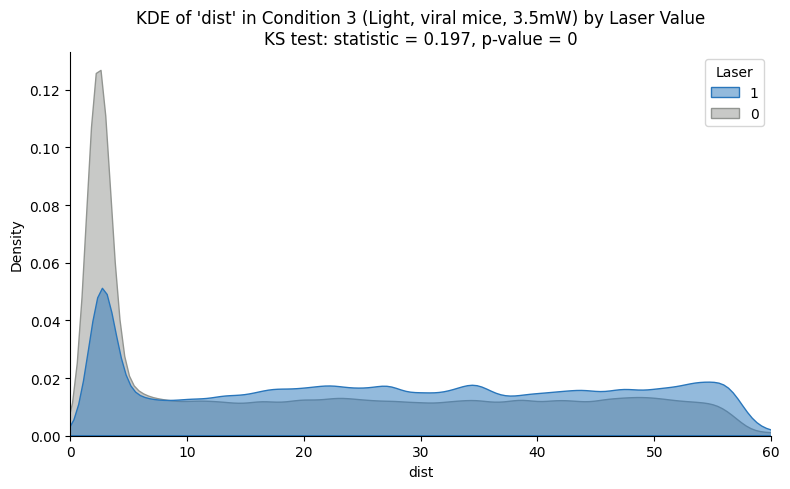

In [69]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '3'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in lower_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, viral mice, 3.5mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


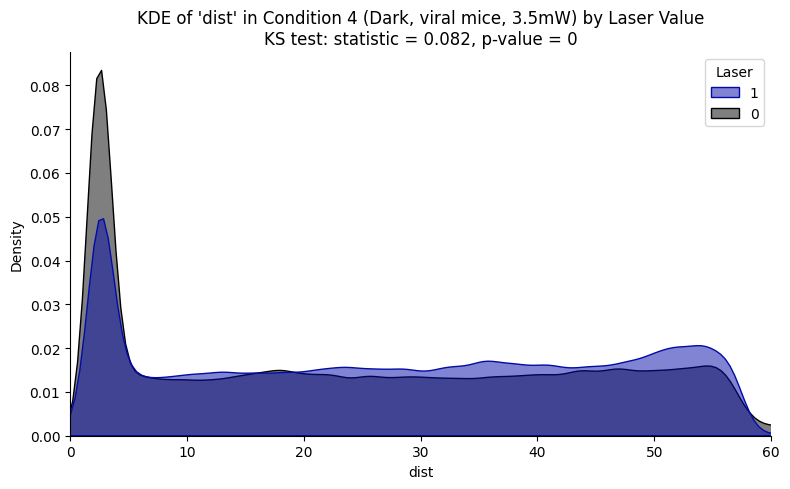

In [70]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '4'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in lower_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, viral mice, 3.5mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


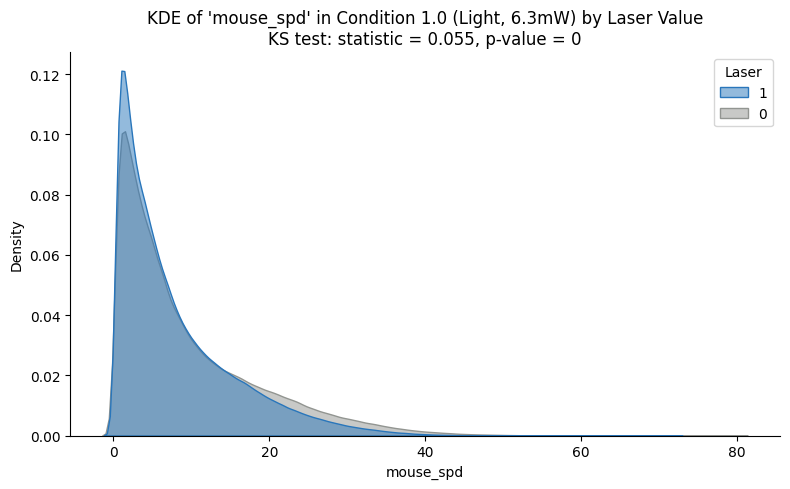

In [59]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in higher_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
# plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


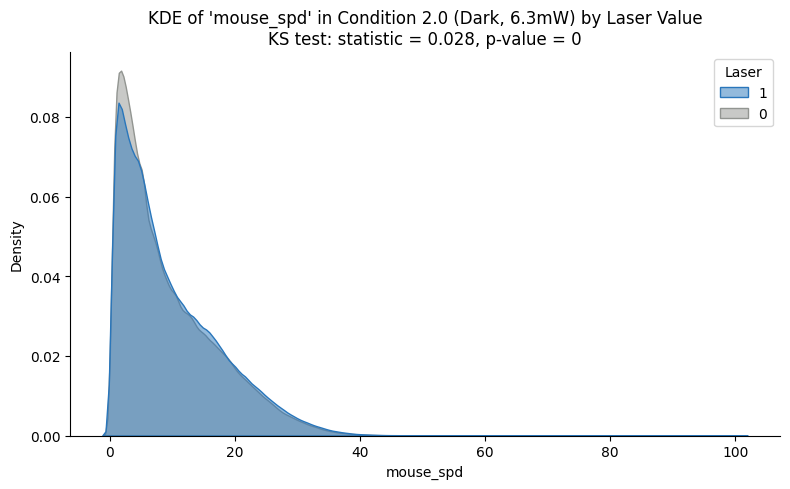

In [60]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in higher_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
# plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


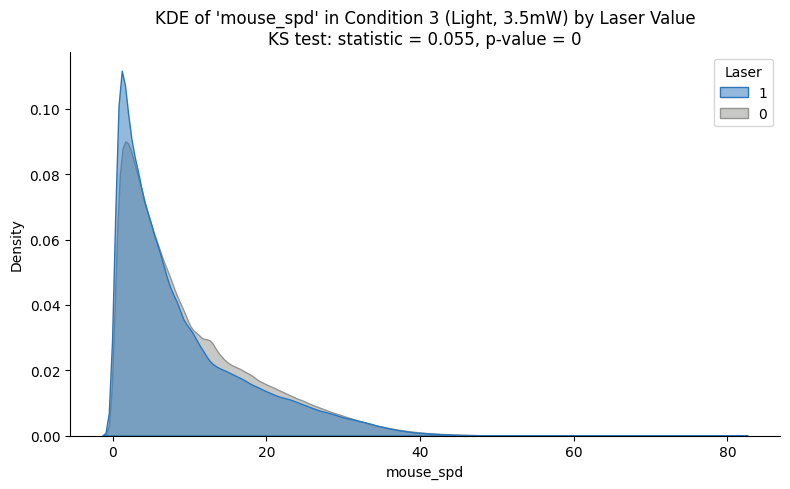

In [61]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '3'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in lower_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, 3.5mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
# plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


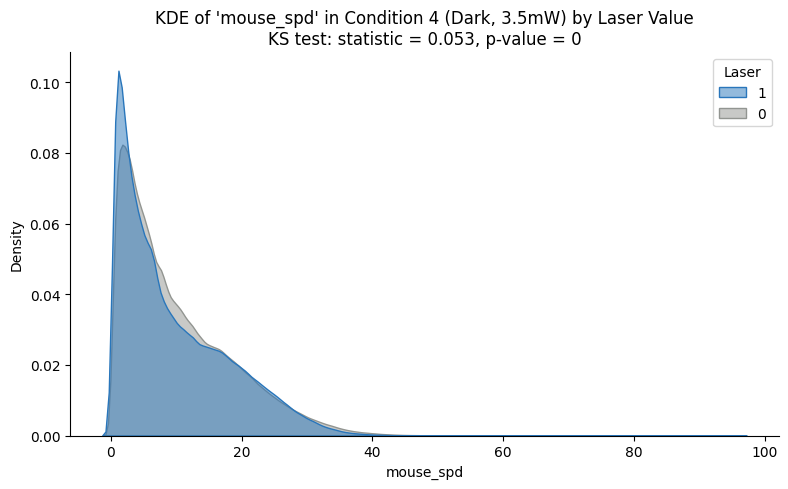

In [62]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '4'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in lower_laser_power.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, 3.5mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
# plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


### see what things would look like if we mark all times longer than 120s to be no catches, this is to match original data

In [51]:
merge_higher_power=cdc(all_data)
nans=np.where(merge_higher_power['captureT']>=120)
nanvals=merge_higher_power['captureT'].iloc[nans[0]]
merge_higher_power=merge_higher_power.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(merge_higher_power['timetointercept']>=120)
nan_attackvals=merge_higher_power['timetointercept'].iloc[nan_attacks[0]]
merge_higher_power=merge_higher_power.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(merge_higher_power['timetoapproach']>=120)
nan_approachvals=merge_higher_power['timetoapproach'].iloc[nan_approach[0]]
merge_higher_power=merge_higher_power.replace({'timetoapproach':nan_approachvals.values}, np.nan)

merge_higher_power['capduration']=merge_higher_power['captureT']-merge_higher_power['timetointercept']


# merge_lower_power=cdc(lower_laser_power)
# nans=np.where(merge_lower_power['captureT']>=120)
# nanvals=merge_lower_power['captureT'].iloc[nans[0]]
# merge_lower_power=merge_lower_power.replace({'captureT':nanvals.values}, np.nan)

# nan_attacks=np.where(merge_lower_power['timetointercept']>=120)
# nan_attackvals=merge_lower_power['timetointercept'].iloc[nan_attacks[0]]
# merge_lower_power=merge_lower_power.replace({'timetointercept':nan_attackvals.values}, np.nan)

# nan_approach=np.where(merge_lower_power['timetoapproach']>=120)
# nan_approachvals=merge_lower_power['timetoapproach'].iloc[nan_approach[0]]
# merge_lower_power=merge_lower_power.replace({'timetoapproach':nan_approachvals.values}, np.nan)

# merge_lower_power['capduration']=merge_lower_power['captureT']-merge_lower_power['timetointercept']

In [52]:
merge_higher_power

,filename,folder_path,condition,laser_value,trials_to_drop,dist,cricket_spd,mouse_spd,az,captureT,...,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,corrected_timetointercept,corrected_capduration,timestamps,mouse
0,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-06-38_mouse-3352,1.0,0.0,left_only,"[32.68468429206058, 32.725606419352125, 33.167...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.820464707482329, 6.110512209286836, 7.87394...","[171.58462568552525, 173.22566975453293, 172.9...",19.790,...,0.333333,1.000000,10.500,2100.0,6.31000,9.290,5.245,14.545,2025-04-21 09:06:38,3352.0
1,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-08-51_mouse-3352,1.0,0.0,left_only,"[nan, 62.564342588310225, 62.57847470293101, 6...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.61692133588647, 10.755066775654555, 14.1260...","[nan, 60.12358977941303, 59.34726236587227, 58...",64.220,...,0.421053,0.125000,13.215,2643.0,8.40875,51.005,9.335,54.885,2025-04-21 09:08:51,3352.0
2,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-11-12_mouse-3352,1.0,1.0,left_only,"[54.24384508435525, 54.21612013599778, 54.1846...","[0.3435990171514824, 0.3412039639408997, 0.332...","[2.257058244768242, 2.4430166816952377, 2.3890...","[71.18839914253688, 62.717046231484645, 55.529...",94.125,...,0.038462,1.000000,89.815,17963.0,9.93950,4.310,89.595,4.530,2025-04-21 09:11:12,3352.0
3,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-14-42_mouse-3352,1.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[2.7024922221323444, 3.107084745186775, 4.1402...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",23.975,...,0.181818,0.500000,4.845,969.0,11.50250,19.130,-8.925,32.900,2025-04-21 09:14:42,3352.0
4,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-04-21_9-17-16_mouse-3352,1.0,1.0,left_only,"[43.52936425762324, 43.53401160997311, 43.5396...","[0.5899277518092662, 0.6615877426062879, 2.121...","[0.18431865367242262, 0.211156300008769, 1.122...","[85.6227143575294, 85.29555370906299, 84.99610...",29.320,...,1.000000,1.000000,12.310,2462.0,10.12450,17.010,12.310,17.010,2025-04-21 09:17:16,3352.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
929,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-38-37_mouse-5096,2.0,1.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[2.814837791276996, 2.8054856961136245, 2.9109...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",27.885,...,0.666667,0.500000,26.520,5304.0,13.17200,1.365,13.530,14.355,2025-11-11 13:38:37,5096.0
930,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-40-36_mouse-5096,2.0,0.0,left_only,"[nan, 40.39356288421923, 40.39763572151864, 40...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.253608241541986, 4.834900882753308, 5.56857...","[nan, 22.87018484616279, 21.525017302599842, 1...",65.320,...,0.294118,0.200000,30.090,6018.0,11.15575,35.230,29.850,35.470,2025-11-11 13:40:36,5096.0
931,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-42-44_mouse-5096,2.0,1.0,left_only,"[61.2818874604661, 61.18894543752171, 61.06944...","[0.742619405079549, 0.5379811470614261, 0.5398...","[10.271955141111093, 12.139244401985835, 12.93...","[124.85829793331533, 112.80212066064826, 110.5...",NaN,...,0.045455,1.000000,114.950,22990.0,12.00050,NaN,114.855,10.195,2025-11-11 13:42:44,5096.0
932,/Volumes/Projects/PreyCapture/ZIActivation/Vir...,2025-11-11_13-45-38_mouse-5096,2.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[12.47024290361598, 14.292803973486915, 15.115...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",21.495,...,0.333333,0.333333,5.500,1100.0,11.57900,15.995,-7.945,29.440,2025-11-11 13:45:38,5096.0

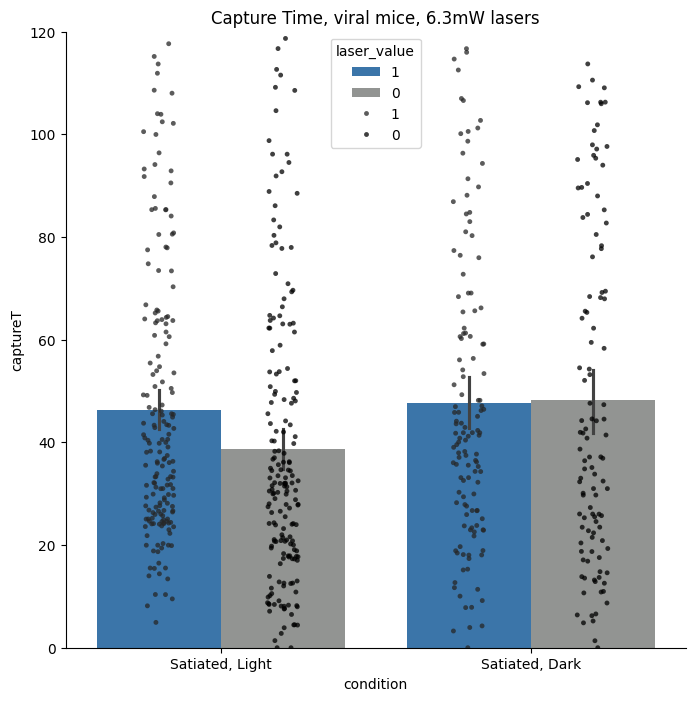

In [53]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=merge_higher_power, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=merge_higher_power, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Time, viral mice, 6.3mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

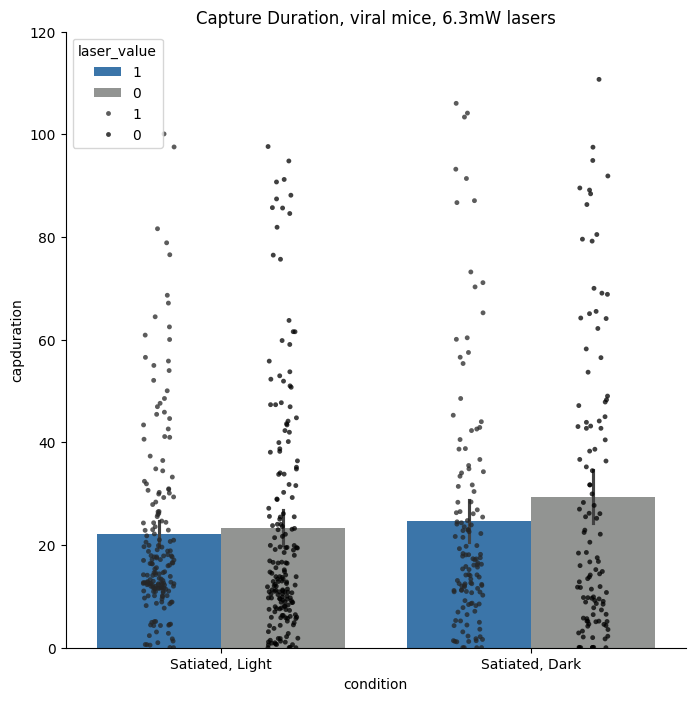

In [56]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=merge_higher_power, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=merge_higher_power, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, viral mice, 6.3mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

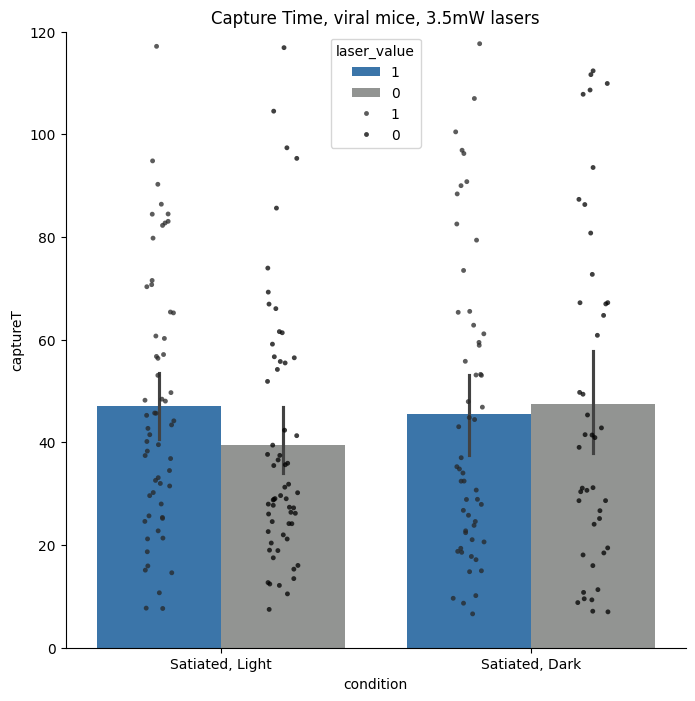

In [81]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=merge_lower_power, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=merge_lower_power, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Time, viral mice, 3.5mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

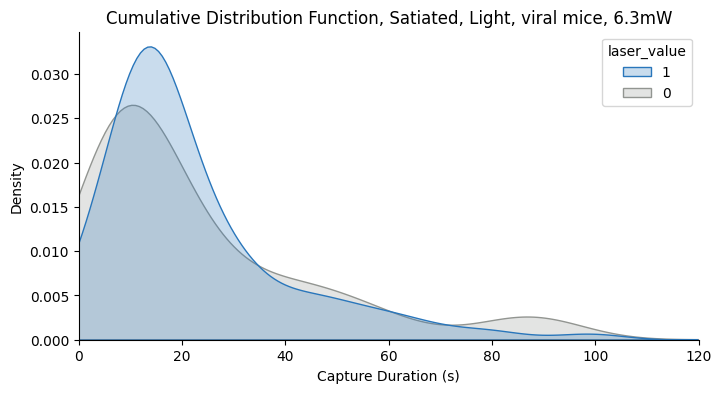

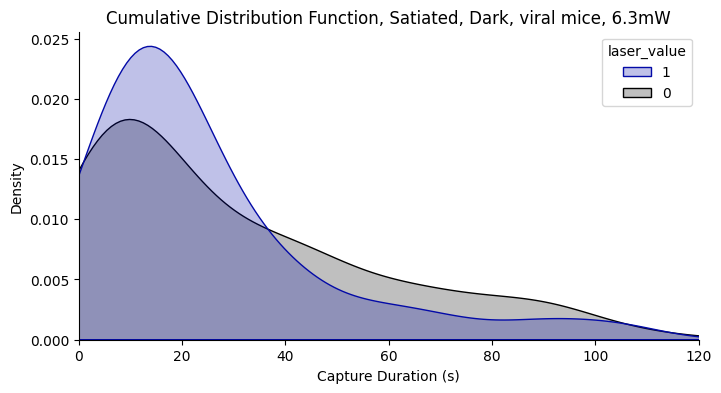

In [57]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_higher_power.iloc[np.where(merge_higher_power['condition']=='1.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_higher_power.iloc[np.where(merge_higher_power['condition']=='2.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()

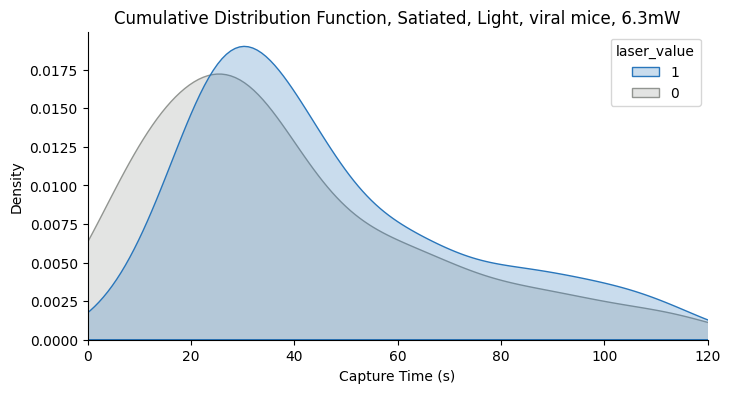

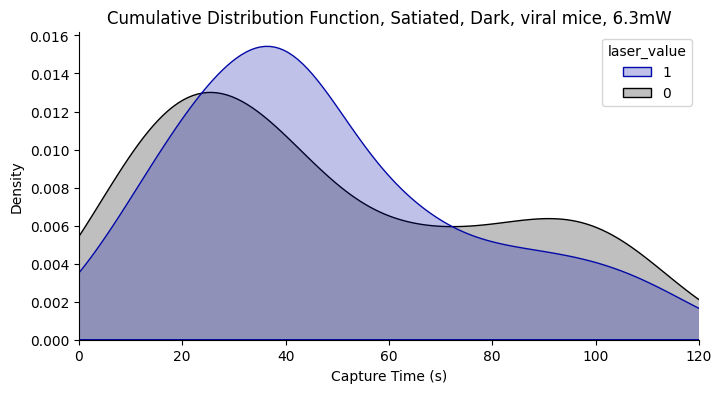

In [58]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_higher_power.iloc[np.where(merge_higher_power['condition']=='1.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_higher_power.iloc[np.where(merge_higher_power['condition']=='2.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()

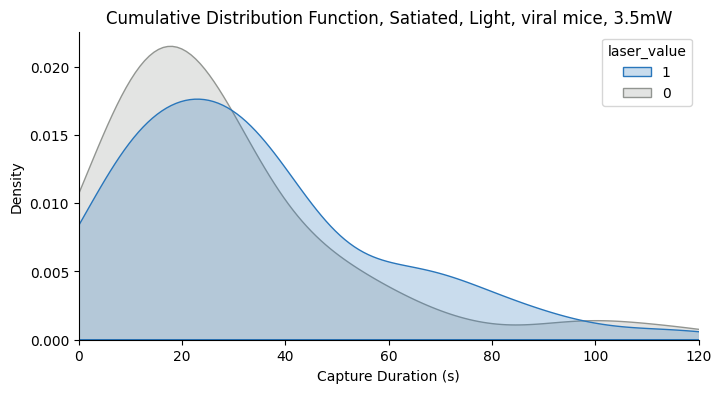

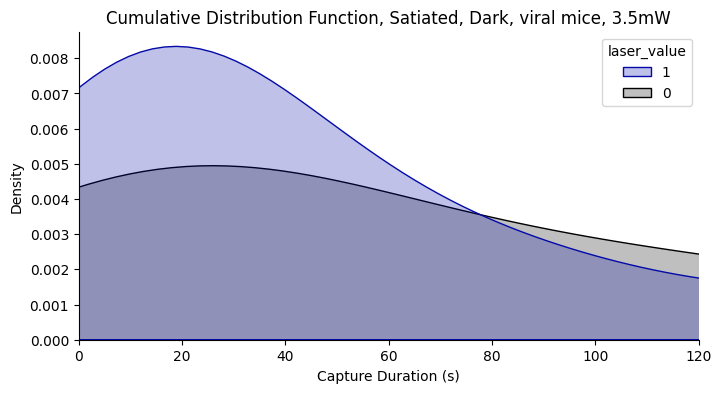

In [87]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_lower_power.iloc[np.where(merge_lower_power['condition']=='3')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=lower_laser_power.iloc[np.where(lower_laser_power['condition']=='4')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()

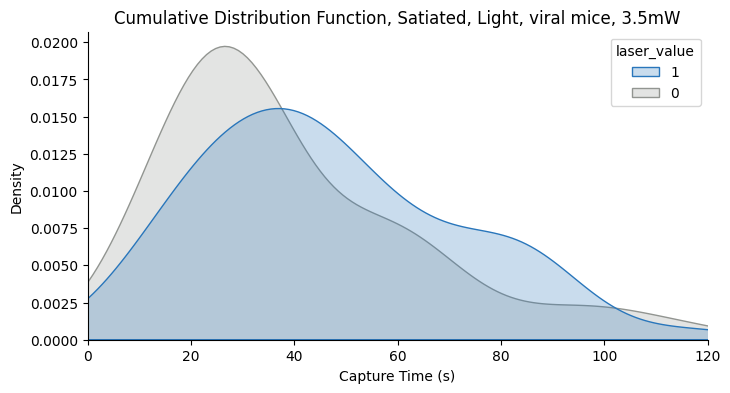

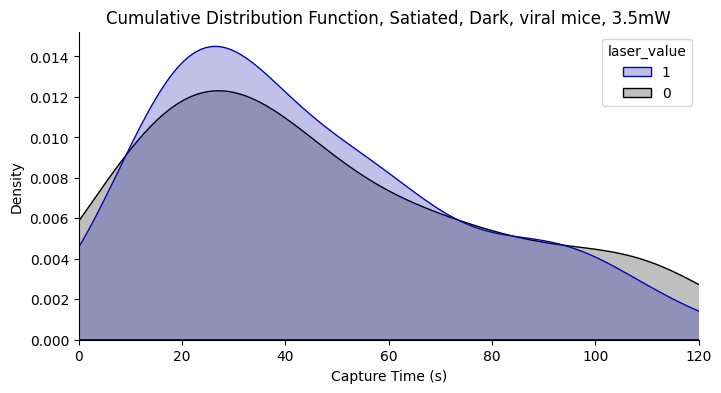

In [88]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_lower_power.iloc[np.where(merge_lower_power['condition']=='3')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, viral mice, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=merge_lower_power.iloc[np.where(merge_lower_power['condition']=='4')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, viral mice, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()

### look at the total distance and prey capture distance traveled across the whole trial

In [98]:
def total_distance_from_xy_array(xy_array):
    if xy_array.shape[0] != 2:
        raise ValueError("Input should have shape (2, N), with first row x and second row y")

    # Reshape to (N, 2) where each row is [x, y]
    positions = xy_array.T  # Now shape is (N, 2)

    # Remove NaNs (in case there are dropped frames)
    positions = positions[~np.isnan(positions).any(axis=1)]

    # Compute total distance
    diffs = np.diff(positions, axis=0)
    step_distances = np.linalg.norm(diffs, axis=1)
    return np.sum(step_distances)

from scipy.signal import savgol_filter

def smooth_xy_array(xy_array, window_length=11, polyorder=2):
    """
    Smooths a 2xN array of x and y positions using Savitzky-Golay filter.
    - window_length must be odd and >= polyorder + 2
    """
    if xy_array.shape[0] != 2:
        raise ValueError("Input must be a 2xN array of x and y coordinates.")

    # Handle short arrays
    if xy_array.shape[1] < window_length:
        return xy_array  # Not enough data to smooth

    smoothed_x = savgol_filter(xy_array[0], window_length, polyorder)
    smoothed_y = savgol_filter(xy_array[1], window_length, polyorder)

    return np.vstack([smoothed_x, smoothed_y])


from scipy.stats import mannwhitneyu

def plot_distance_distributions_by_condition(df):
    conditions = sorted(df['condition'].unique())
    distance_columns = [
        ('mouse_total_distance', 'Total Distance'),
        ('preycap_distance_traveled', 'Prey Capture Distance')
    ]

    for distance_column, title_label in distance_columns:
        for cond in conditions:
            plt.figure(figsize=(8, 6))
            subset = df[df['condition'] == cond]

            group_stats = {}
            for laser_val, color, label in zip([0, 1], ['#929591', '#2976bb'], ['Laser OFF', 'Laser ON']):
                laser_subset = subset[subset['laser_value'] == laser_val]
                valid_data = laser_subset[distance_column].dropna()

                if len(valid_data) > 1:
                    sns.kdeplot(
                        x=valid_data,
                        fill=True,
                        alpha=0.5,
                        linewidth=2,
                        label=label,
                        color=color
                    )
                    mean = valid_data.mean()
                    std = valid_data.std()

                    # Add vertical mean line
                    plt.axvline(mean, color=color, linestyle='--', linewidth=1.5)

                    # Store stats for p-value test
                    group_stats[laser_val] = valid_data

                    # Add text annotation
                    plt.text(
                        mean,
                        plt.ylim()[1]*0.9 if laser_val == 0 else plt.ylim()[1]*0.8,
                        f"Mean = {mean:.1f} ± {std:.1f}",
                        color=color,
                        ha='center',
                        fontsize=10,
                        bbox=dict(facecolor='white', edgecolor=color, alpha=0.6)
                    )
                else:
                    print(f"⚠️ Not enough valid data for condition {cond}, laser {laser_val}, distance: {distance_column} — skipping KDE")

            # Optional: statistical test between laser=0 and laser=1
            if 0 in group_stats and 1 in group_stats:
                stat, pval = mannwhitneyu(group_stats[0], group_stats[1], alternative='two-sided')
                plt.text(
                    0.95, 0.95,
                    f"Mann-Whitney U p = {pval:.3f}",
                    transform=plt.gca().transAxes,
                    ha='right',
                    va='bottom',
                    fontsize=11,
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='black')
                )

            plt.title(f"{title_label} — Condition {cond}")
            plt.xlabel(f"{title_label} (units)")
            plt.ylabel("Density")
            plt.xlim(0,2500)
            plt.legend(loc='lower right')
            plt.tight_layout()
            sns.despine()
            plt.show()


        

In [92]:
FPS = 200
max_frames = int(125 * FPS)

results = []
cols_to_keep = ['filename', 'condition', 'laser_value', 'captureT', 'cricketdrop', 'captureframe']

for idx, row in higher_laser_power[cols_to_keep].iterrows():
    filename = row['filename']
    capture_time = row['captureT']
    drop_frame = row['cricketdrop']
    capture_frame = row['captureframe']

    try:
        # Extract tracking points
        mouse_xy, cricket_p, cricket_xy, rear_xy, lear_xy, spine_xy, cricket_front, cricket_back = preycap.extract_points(
            filename, ['Rear', 'Lear', 'anteriorC', 'posteriorC', 'spine']
        )

        # Limit to first 125s if needed
        if pd.isna(capture_time) or capture_time > 125:
            mouse_xy = mouse_xy[:, :max_frames]

        # Smooth full trajectory
        smoothed_mouse_xy = smooth_xy_array(mouse_xy)

        # Total distance across all time
        total_mouse_distance = total_distance_from_xy_array(smoothed_mouse_xy)

        # --- Prey capture distance ---
        preycap_distance = np.nan  # default if drop/capture info is missing

        if pd.notna(drop_frame) and pd.notna(capture_frame):
            drop_frame = int(drop_frame)
            capture_frame = int(capture_frame)

            if 0 <= drop_frame < capture_frame <= mouse_xy.shape[1]:
                segment = mouse_xy[:, drop_frame:capture_frame]
                segment_smoothed = smooth_xy_array(segment)
                preycap_distance = total_distance_from_xy_array(segment_smoothed)

        # Store results
        result_row = {
            'filename': filename,
            'condition': row['condition'],
            'laser_value': row['laser_value'],
            'captureT': capture_time,
            'mouse_total_distance': total_mouse_distance,
            'preycap_distance_traveled': preycap_distance
        }
        results.append(result_row)

    except Exception as e:
        print(f"⚠️ Failed on {filename}: {e}")
        continue

# Final DataFrame
distance_df = pd.DataFrame(results)
print(distance_df.head())


                                            filename condition  laser_value  \
0  /Volumes/Projects/PreyCapture/ZIActivation/Vir...       1.0          0.0   
1  /Volumes/Projects/PreyCapture/ZIActivation/Vir...       1.0          0.0   
2  /Volumes/Projects/PreyCapture/ZIActivation/Vir...       1.0          1.0   
3  /Volumes/Projects/PreyCapture/ZIActivation/Vir...       1.0          0.0   
4  /Volumes/Projects/PreyCapture/ZIActivation/Vir...       1.0          1.0   

   captureT  mouse_total_distance  preycap_distance_traveled  
0    29.400            336.298899                 327.655513  
1    64.220            896.992903                 844.769279  
2    84.565            986.800642                 917.291911  
3    39.130            505.464460                 495.656690  
4       NaN            872.021946                        NaN  


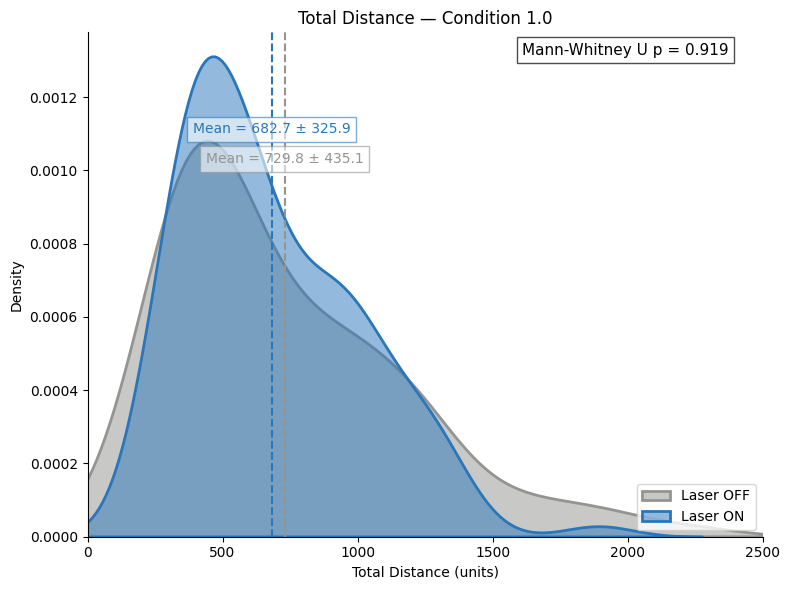

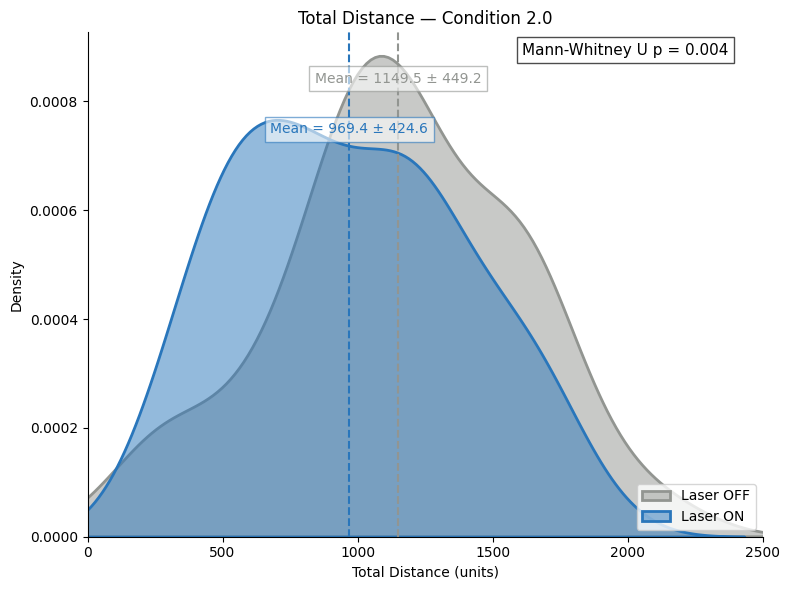

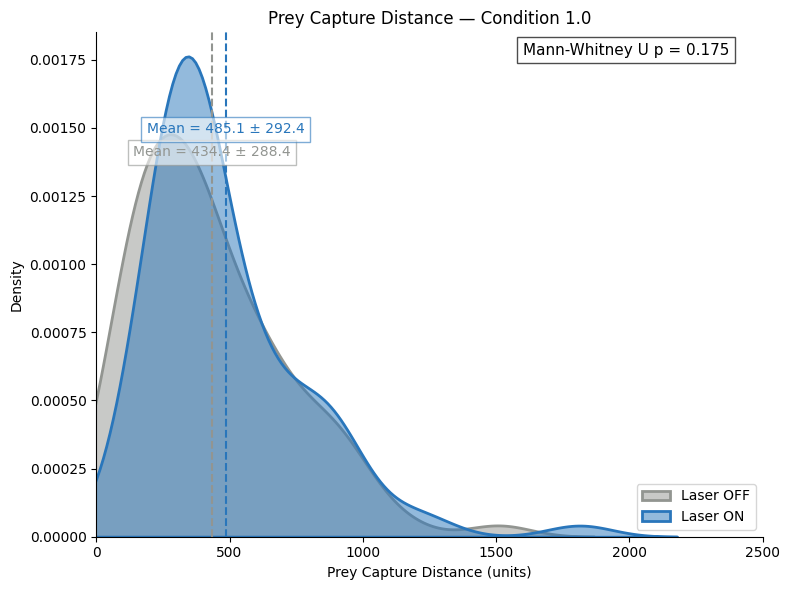

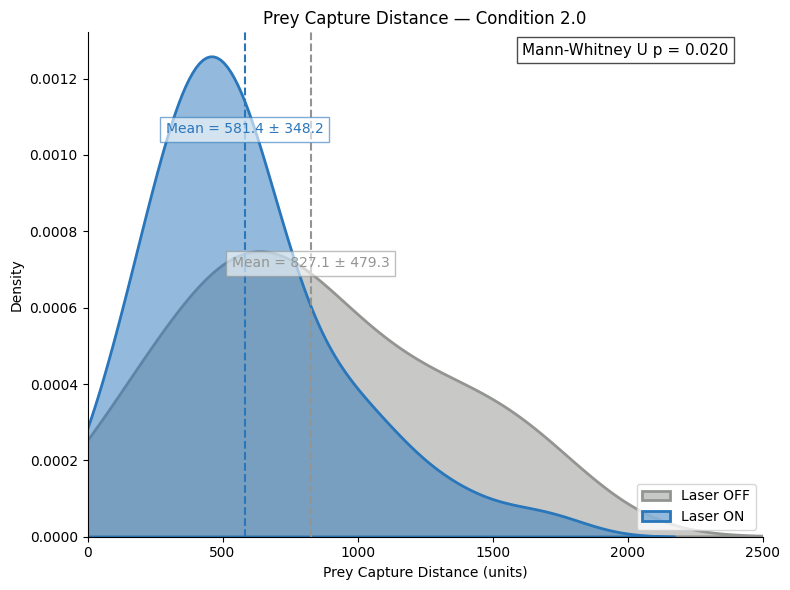

In [99]:
plot_distance_distributions_by_condition(distance_df)

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_12731/2299713304.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_data['dist_50_after_drop'] = np.nan


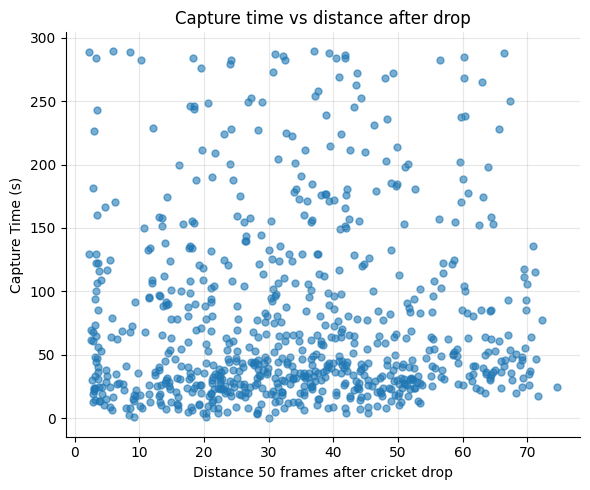

In [21]:
FRAME_OFFSET = 50

def dist_after_drop(dist, drop, offset=FRAME_OFFSET):
    try:
        dist_arr = np.asarray(dist, dtype=float)
    except Exception:
        return np.nan

    idx = int(drop + offset)

    if idx < 0 or idx >= len(dist_arr):
        return np.nan

    return dist_arr[idx]

mask = (
    all_data['dist'].notna() &
    all_data['cricketdrop'].notna() &
    all_data['captureT'].notna() &
    (all_data['cricketdrop'] + FRAME_OFFSET
     < all_data['dist'].str.len())
)

all_data['dist_50_after_drop'] = np.nan

for i in all_data.index[mask]:
    all_data.at[i, 'dist_50_after_drop'] = dist_after_drop(
        all_data.at[i, 'dist'],
        all_data.at[i, 'cricketdrop']
    )

mask.sum(), len(all_data)

plot_df = all_data.dropna(
    subset=['dist_50_after_drop', 'captureT']
)

plt.figure(figsize=(6,5))
plt.scatter(
    plot_df['dist_50_after_drop'],
    plot_df['captureT'],
    alpha=0.6,
    s=25
)

plt.xlabel('Distance 50 frames after cricket drop')
plt.ylabel('Capture Time (s)')
plt.title('Capture time vs distance after drop')
# plt.ylim(0,20)
# plt.xlim(0,20)
plt.grid(alpha=0.3)
plt.tight_layout()
sns.despine()
plt.show()

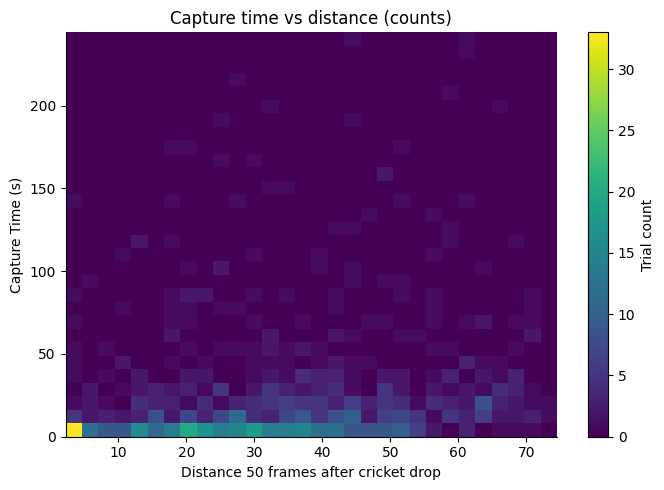

In [22]:
plt.figure(figsize=(7, 5))

h = plt.hist2d(
    plot_df['dist_50_after_drop'],
    plot_df['corrected_timetointercept'],
    bins=[30, 30],   # adjust bin resolution
    cmap='viridis'
)


plt.xlabel('Distance 50 frames after cricket drop')
plt.ylabel('Capture Time (s)')
plt.title('Capture time vs distance (counts)')
plt.colorbar(h[3], label='Trial count')
# plt.ylim(0,30)
# plt.xlim(1,30)
sns.despine()
plt.tight_layout()
plt.show()

In [23]:
def plot_metric_by_distance_bins(
    df,
    dist_col='dist_50_after_drop',
    metric_col='corrected_timetointercept',
    max_dist=60,
    dist_bin_size=2,
    metric_bin_size=10,
    plot_type='stacked',   # 'stacked' or 'heatmap'
    metric_label='Metric (s)',
    title=None,
):
    """
    Plot percentage distribution of a metric across distance bins.

    Percentages are normalized WITHIN each distance bin.

    Parameters
    ----------
    df : pandas.DataFrame
    dist_col : str
        Column containing distance values
    metric_col : str
        Column to bin and plot (e.g. capture time)
    max_dist : float
        Maximum distance to include
    dist_bin_size : float
        Bin width for distance
    metric_bin_size : float
        Bin width for metric (e.g. seconds)
    plot_type : str
        'stacked' or 'heatmap'
    metric_label : str
        Label for legend / y-axis
    title : str
        Plot title
    """

    # ----------------------------
    # Filter + cleanup
    # ----------------------------
    plot_df = (
        df[[dist_col, metric_col]]
        .dropna()
        .copy()
    )

    plot_df = plot_df[plot_df[dist_col] <= max_dist]

    if plot_df.empty:
        print("No data left after filtering.")
        return

    # ----------------------------
    # Define bins
    # ----------------------------
    dist_bins = np.arange(0, max_dist + dist_bin_size, dist_bin_size)

    max_metric = np.ceil(plot_df[metric_col].max() / metric_bin_size) * metric_bin_size
    metric_bins = np.arange(0, max_metric + metric_bin_size, metric_bin_size)

    metric_labels = [
        f'{int(metric_bins[i])}–{int(metric_bins[i+1])}'
        for i in range(len(metric_bins) - 1)
    ]

    # ----------------------------
    # Bin the data
    # ----------------------------
    plot_df['dist_bin'] = pd.cut(
        plot_df[dist_col],
        bins=dist_bins
    )

    plot_df['metric_bin'] = pd.cut(
        plot_df[metric_col],
        bins=metric_bins,
        labels=metric_labels,
        right=False
    )

    # ----------------------------
    # Count & normalize
    # ----------------------------
    counts = (
        plot_df
        .groupby(['dist_bin', 'metric_bin'])
        .size()
        .unstack(fill_value=0)
    )

    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    # ----------------------------
    # Plot
    # ----------------------------
    if plot_type == 'stacked':
        percentages.plot(
            kind='bar',
            stacked=True,
            figsize=(10, 5),
            colormap='Spectral'
        )

        plt.ylabel('Percentage of trials (%)')
        plt.xlabel('Distance bin')
        plt.legend(
            title=metric_label,
            bbox_to_anchor=(1.05, 1),
            loc='upper left'
        )

    elif plot_type == 'heatmap':
        plt.figure(figsize=(8, 5))
        sns.heatmap(
            percentages.T,
            cmap='Spectral',
            annot=True,
            fmt='.1f',
            cbar_kws={'label': 'Percentage (%)'}
        )

        plt.xlabel('Distance bin')
        plt.ylabel(metric_label)

    else:
        raise ValueError("plot_type must be 'stacked' or 'heatmap'")

    if title is not None:
        plt.title(title)

    plt.tight_layout()
    plt.show()


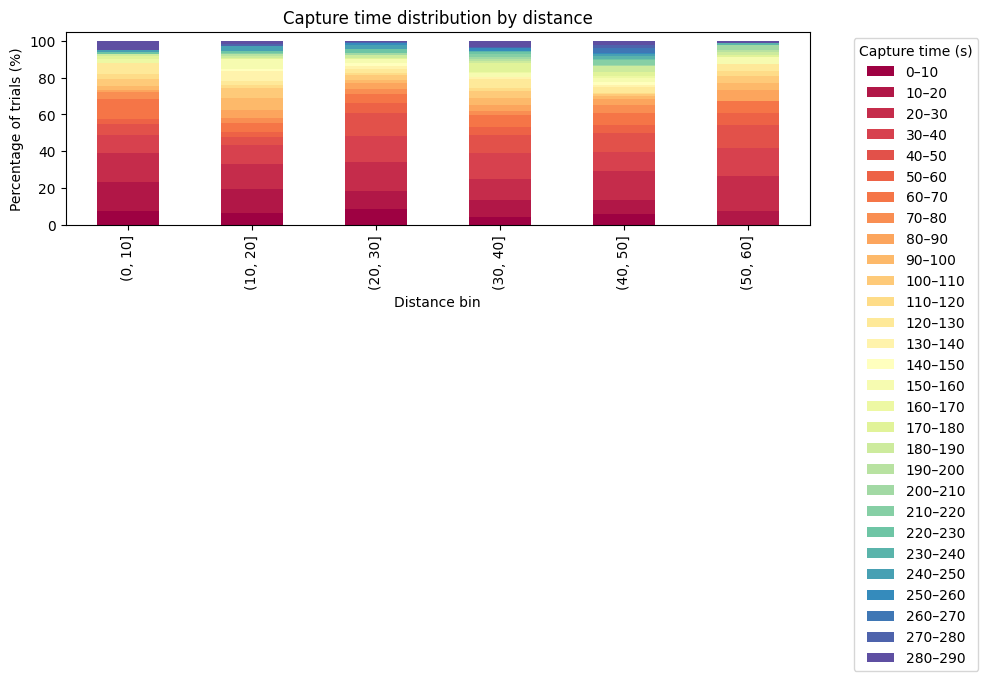

In [24]:
plot_metric_by_distance_bins(
    all_data,
    metric_col='captureT',
    metric_label='Capture time (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='stacked',
    title='Capture time distribution by distance'
)

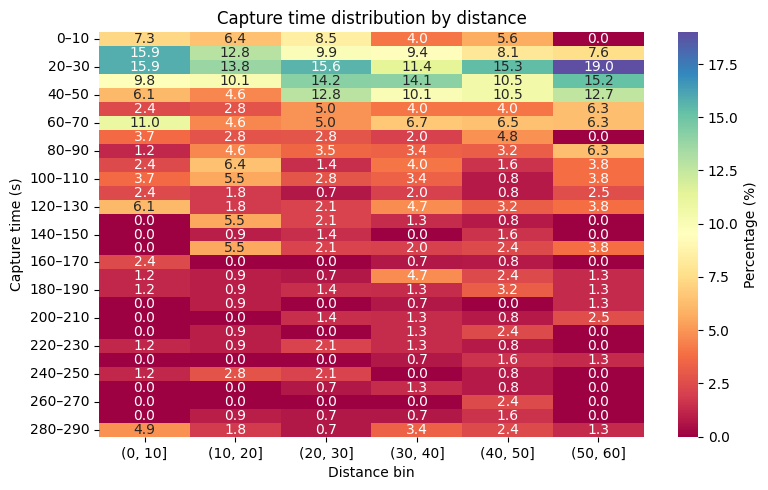

In [25]:
plot_metric_by_distance_bins(
    all_data,
    metric_col='captureT',
    metric_label='Capture time (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='heatmap',
    title='Capture time distribution by distance'
)

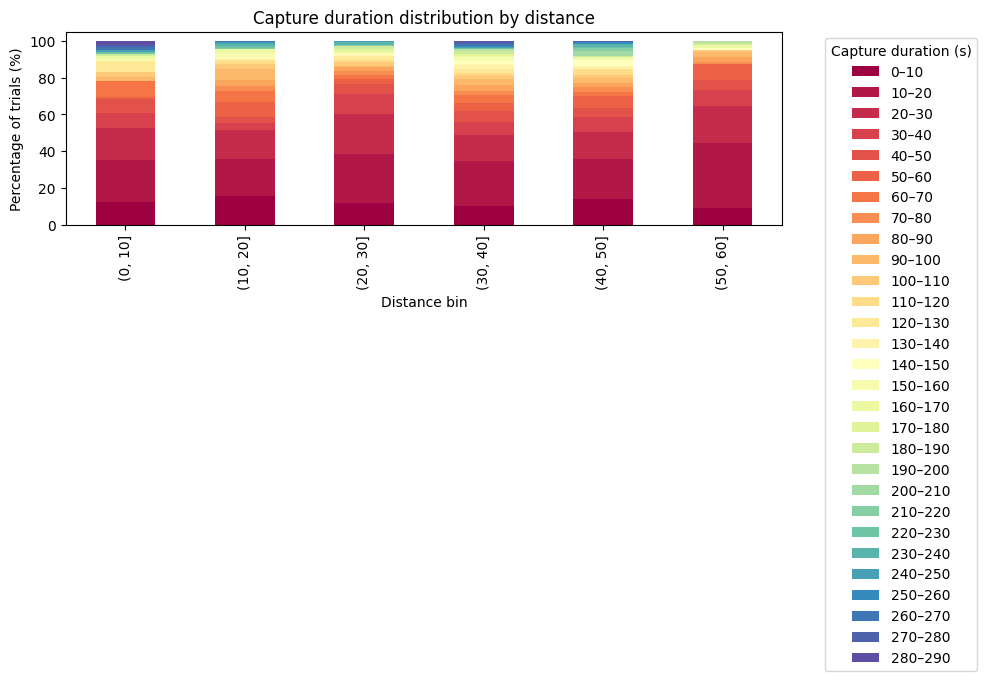

In [26]:
plot_metric_by_distance_bins(
    all_data,
    metric_col='corrected_capduration',
    metric_label='Capture duration (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='stacked',
    title='Capture duration distribution by distance'
)

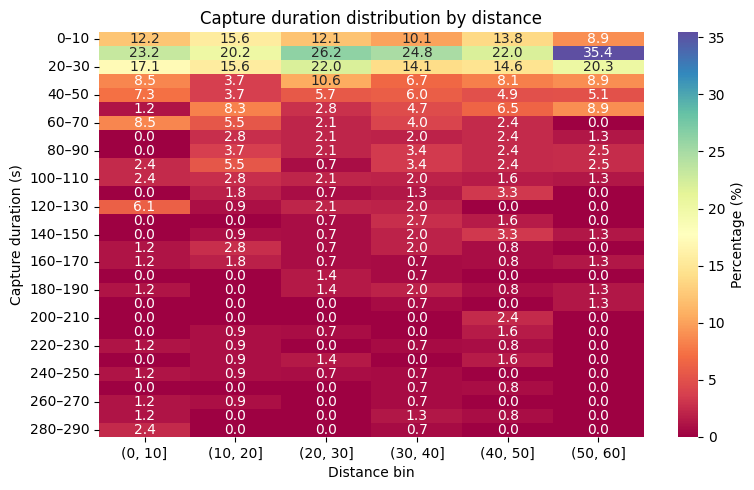

In [27]:
plot_metric_by_distance_bins(
    all_data,
    metric_col='corrected_capduration',
    metric_label='Capture duration (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='heatmap',
    title='Capture duration distribution by distance'
)

In [28]:
# import pandas as pd
# import numpy as np
from scipy.stats import shapiro, levene, f_oneway, kruskal
import scikit_posthocs as sp

def distance_bin_statistics(df, dist_col='dist_bin', metric_col='corrected_timetointercept'):
    """
    Perform statistics to compare metric across distance bins.
    
    Parameters
    ----------
    df : pd.DataFrame
        Must include 'dist_bin' (categorical) and metric column.
    dist_col : str
        Column for distance bins
    metric_col : str
        Continuous variable to compare across bins
    
    Returns
    -------
    results : dict
        Contains:
        - 'normality': Shapiro p-values per bin
        - 'variance_homogeneity': Levene test p
        - 'overall_test': ANOVA or Kruskal-Wallis result
        - 'posthoc': Dunn test results (Bonferroni)
    """
    
    # --------------------------
    # Filter out bins with <3 trials
    # --------------------------
    valid_bins = df.groupby(dist_col).filter(lambda x: len(x) >= 3)
    
    if valid_bins.empty:
        raise ValueError("No distance bins have >= 3 trials. Adjust binning or filter criteria.")
    
    # --------------------------
    # Normality (Shapiro) per bin
    # --------------------------
    normality = {}
    for name, group in valid_bins.groupby(dist_col):
        stat, p = shapiro(group[metric_col])
        normality[name] = p
    
    # --------------------------
    # Homogeneity of variances (Levene)
    # --------------------------
    groups_list = [group[metric_col].values for _, group in valid_bins.groupby(dist_col)]
    stat_levene, p_levene = levene(*groups_list)
    
    # --------------------------
    # Decide test
    # --------------------------
    normal = all(p>0.05 for p in normality.values())
    equal_var = p_levene > 0.05
    
    if normal and equal_var:
        # Parametric ANOVA
        stat_overall, p_overall = f_oneway(*groups_list)
        test_name = 'ANOVA'
    else:
        # Non-parametric Kruskal-Wallis
        stat_overall, p_overall = kruskal(*groups_list)
        test_name = 'Kruskal-Wallis'
    
    # --------------------------
    # Post-hoc (Dunn's test, Bonferroni)
    # --------------------------
    # Convert distance bin to categorical codes for Dunn
    valid_bins = valid_bins.copy()
    valid_bins['dist_bin_code'] = valid_bins[dist_col].astype('category').cat.codes
    dunn = sp.posthoc_dunn(
        valid_bins,
        val_col=metric_col,
        group_col='dist_bin_code',
        p_adjust='bonferroni'
    )
    
    # Rename rows/cols to distance bin labels
    dunn.index = valid_bins[dist_col].astype('category').cat.categories
    dunn.columns = valid_bins[dist_col].astype('category').cat.categories
    
    # --------------------------
    # Return results
    # --------------------------
    results = {
        'normality': normality,
        'variance_homogeneity_p': p_levene,
        'overall_test': {'test': test_name, 'stat': stat_overall, 'p': p_overall},
        'posthoc': dunn
    }
    
    return results


In [30]:
# Make sure your df has distance bins (like in the plotting script)
plot_df = all_data.dropna(subset=['dist_50_after_drop', 'captureT']).copy()
plot_df = plot_df[plot_df['dist_50_after_drop'] <= 60]

# Create distance bins (10-unit bins)
plot_df['dist_bin'] = pd.cut(plot_df['dist_50_after_drop'], bins=np.arange(0, 70, 10))

# Run statistics
stats_results = distance_bin_statistics(plot_df)

# View outputs
print("Normality per bin (Shapiro p-values):")
print(stats_results['normality'])
print("\nLevene p (variance homogeneity):", stats_results['variance_homogeneity_p'])
print("\nOverall test result:")
print(stats_results['overall_test'])
print("\nPost-hoc Dunn test (Bonferroni corrected):")
print(stats_results['posthoc'])


Normality per bin (Shapiro p-values):
{Interval(0, 10, closed='right'): 1.0008899833633904e-14, Interval(10, 20, closed='right'): 1.7783203468760886e-14, Interval(20, 30, closed='right'): 6.992724116339518e-18, Interval(30, 40, closed='right'): 7.73708447731676e-18, Interval(40, 50, closed='right'): 8.259851617236741e-16, Interval(50, 60, closed='right'): 1.777313951597362e-11}

Levene p (variance homogeneity): 0.07739190588059916

Overall test result:
{'test': 'Kruskal-Wallis', 'stat': 73.64856705588993, 'p': 1.7805312006845237e-14}

Post-hoc Dunn test (Bonferroni corrected):
               (0, 10]  (10, 20]  (20, 30]      (30, 40]      (40, 50]  \
(0, 10]   1.000000e+00  0.000103  0.000022  5.180264e-10  2.499248e-11   
(10, 20]  1.031857e-04  1.000000  1.000000  6.630044e-01  1.220989e-01   
(20, 30]  2.166437e-05  1.000000  1.000000  5.934174e-01  9.604707e-02   
(30, 40]  5.180264e-10  0.663004  0.593417  1.000000e+00  1.000000e+00   
(40, 50]  2.499248e-11  0.122099  0.096047  1.

In [31]:
import pandas as pd

def summarize_dunn(dunn_matrix, df, dist_col='dist_bin', metric_col='corrected_timetointercept', alpha=0.05):
    """
    Summarize significant pairwise comparisons from a Dunn post-hoc matrix.
    
    Parameters
    ----------
    dunn_matrix : pd.DataFrame
        Dunn test p-values, rows/cols = distance bins
    df : pd.DataFrame
        Original data with distance bins and metric
    dist_col : str
        Column name for distance bins
    metric_col : str
        Column name for metric
    alpha : float
        Significance threshold (default 0.05)
    
    Returns
    -------
    summary : pd.DataFrame
        Columns: Bin 1, Bin 2, p-value, Mean Bin 1, Mean Bin 2, Direction
    """
    
    results = []
    # Iterate over upper triangle (no duplicates)
    bins = dunn_matrix.index
    for i in range(len(bins)):
        for j in range(i+1, len(bins)):
            bin1 = bins[i]
            bin2 = bins[j]
            pval = dunn_matrix.loc[bin1, bin2]
            if pval < alpha:
                mean1 = df[df[dist_col] == bin1][metric_col].mean()
                mean2 = df[df[dist_col] == bin2][metric_col].mean()
                if mean1 > mean2:
                    direction = f"{bin1} > {bin2}"
                elif mean1 < mean2:
                    direction = f"{bin1} < {bin2}"
                else:
                    direction = "equal"
                
                results.append({
                    'Bin 1': bin1,
                    'Bin 2': bin2,
                    'p-value': pval,
                    f'Mean {bin1}': mean1,
                    f'Mean {bin2}': mean2,
                    'Direction': direction
                })
    
    summary = pd.DataFrame(results)
    return summary


In [32]:
summary = summarize_dunn(stats_results['posthoc'], plot_df)
pd.set_option('display.max_rows', None)  # show all rows
summary


,Bin 1,Bin 2,p-value,"Mean (0, 10]","Mean (10, 20]",Direction,"Mean (20, 30]","Mean (30, 40]","Mean (40, 50]","Mean (50, 60]"
0,"(0, 10]","(10, 20]",1.031857e-04,11.04,23.680642,"(0, 10] < (10, 20]",NaN,NaN,NaN,NaN
1,"(0, 10]","(20, 30]",2.166437e-05,11.04,NaN,"(0, 10] < (20, 30]",21.902128,NaN,NaN,NaN
2,"(0, 10]","(30, 40]",5.180264e-10,11.04,NaN,"(0, 10] < (30, 40]",NaN,22.386711,NaN,NaN
3,"(0, 10]","(40, 50]",2.499248e-11,11.04,NaN,"(0, 10] < (40, 50]",NaN,NaN,28.778226,NaN
4,"(0, 10]","(50, 60]",1.921253e-12,11.04,NaN,"(0, 10] < (50, 60]",NaN,NaN,NaN,32.773038
5,"(10, 20]","(50, 60]",8.266528e-03,NaN,23.680642,"(10, 20] < (50, 60]",NaN,NaN,NaN,32.773038
6,"(20, 30]","(50, 60]",5.816478e-03,NaN,NaN,"(20, 30] < (50, 60]",21.902128,NaN,NaN,32.773038


In [33]:
import matplotlib.pyplot as plt
import numpy as np

def plot_capture_vs_distance_with_stats(df, dist_col='dist_bin', metric_col='corrected_timetointercept',
                                        dunn_matrix=None, bin_labels=None, alpha=0.05,
                                        figsize=(10,5), bar_width=0.8, palette='tab10'):
    """
    Plot mean capture metric per distance bin with Dunn post-hoc significance annotations.
    
    Parameters
    ----------
    df : pd.DataFrame
        Data with distance bins and metric
    dist_col : str
        Column for distance bins
    metric_col : str
        Metric to plot
    dunn_matrix : pd.DataFrame, optional
        Dunn post-hoc p-value matrix
    bin_labels : list, optional
        Labels for x-axis bins
    alpha : float
        Significance threshold
    figsize : tuple
        Figure size
    bar_width : float
        Width of bars
    palette : str
        Matplotlib colormap
    """
    
    # Compute mean and sem per bin
    stats_df = df.groupby(dist_col)[metric_col].agg(['mean','sem']).reset_index()
    x = np.arange(len(stats_df))
    
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(x, stats_df['mean'], yerr=stats_df['sem'], width=bar_width, color=plt.get_cmap(palette).colors[:len(stats_df)], capsize=5)
    
    # X-axis labels
    if bin_labels is None:
        bin_labels = [str(b) for b in stats_df[dist_col]]
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels, rotation=45)
    ax.set_xlabel('Distance bin')
    ax.set_ylabel(metric_col)
    ax.set_title(f'{metric_col} by distance bin')
    
    # ----------------------
    # Add significance stars from Dunn matrix
    # ----------------------
    if dunn_matrix is not None:
        bins = stats_df[dist_col].tolist()
        y_max = stats_df['mean'].max() + stats_df['sem'].max() * 2
        h = y_max * 0.05  # height increment for stars
        star_count = 0
        
        for i in range(len(bins)):
            for j in range(i+1, len(bins)):
                pval = dunn_matrix.loc[bins[i], bins[j]]
                if pval < alpha:
                    # Decide number of stars
                    if pval < 0.001:
                        stars = '***'
                    elif pval < 0.01:
                        stars = '**'
                    else:
                        stars = '*'
                    
                    # Position stars above bars
                    y = y_max + star_count * h
                    x1, x2 = x[i], x[j]
                    ax.plot([x1, x1, x2, x2], [y, y+h/4, y+h/4, y], lw=1.5, c='k')  # line
                    ax.text((x1+x2)/2, y+h/4, stars, ha='center', va='bottom', color='k')
                    star_count += 1
    
    plt.tight_layout()
    plt.show()


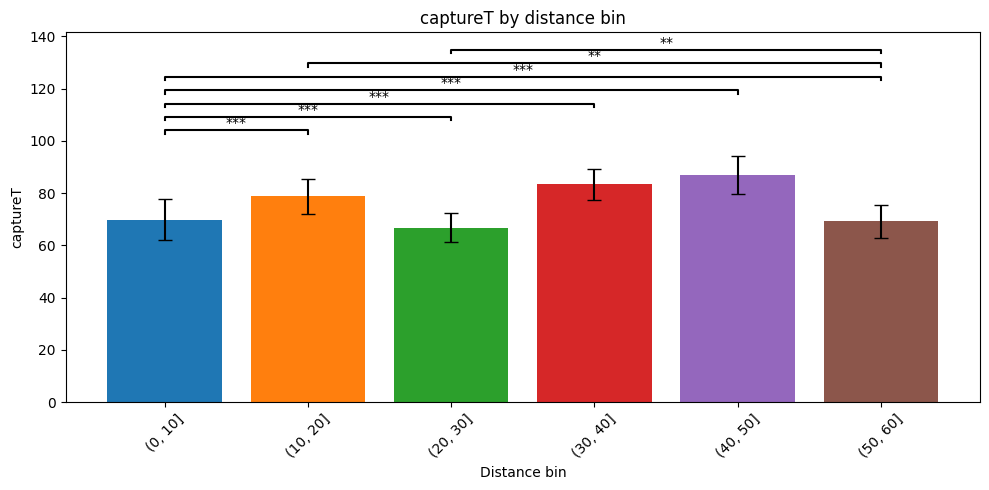

In [34]:
# Ensure plot_df has distance bins and is filtered
plot_df = all_data.dropna(subset=['dist_50_after_drop', 'captureT']).copy()
plot_df = plot_df[plot_df['dist_50_after_drop'] <= 60]
plot_df['dist_bin'] = pd.cut(plot_df['dist_50_after_drop'], bins=np.arange(0, 62, 10))

# Run stats (if not done already)
stats_results = distance_bin_statistics(plot_df)

# Plot with stars
plot_capture_vs_distance_with_stats(
    plot_df,
    dist_col='dist_bin',
    metric_col='captureT',
    dunn_matrix=stats_results['posthoc']
)


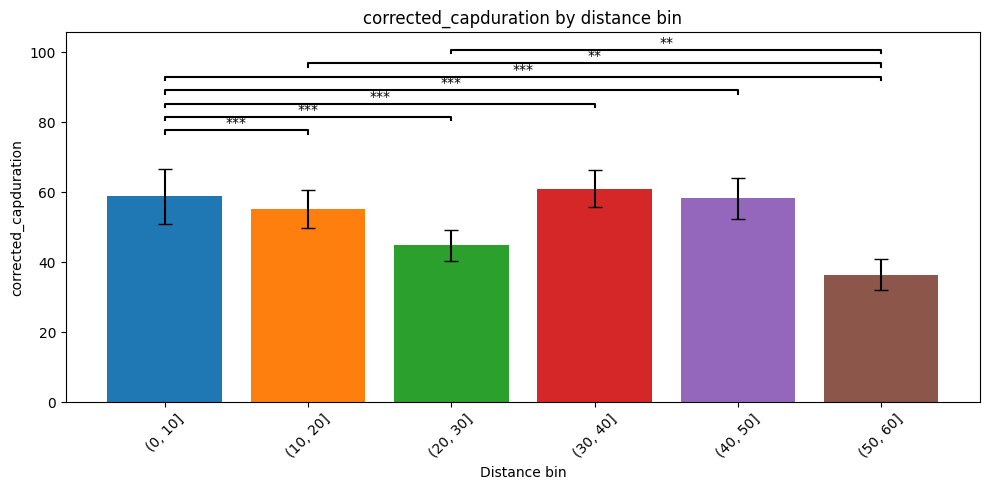

In [36]:
# Ensure plot_df has distance bins and is filtered
plot_df = all_data.dropna(subset=['dist_50_after_drop', 'corrected_capduration']).copy()
plot_df = plot_df[plot_df['dist_50_after_drop'] <= 60]
plot_df['dist_bin'] = pd.cut(plot_df['dist_50_after_drop'], bins=np.arange(0, 62, 10))

# Run stats (if not done already)
stats_results = distance_bin_statistics(plot_df)

# Plot with stars
plot_capture_vs_distance_with_stats(
    plot_df,
    dist_col='dist_bin',
    metric_col='corrected_capduration',
    dunn_matrix=stats_results['posthoc']
)
